# 1. Importation des biblio

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
import torch
import torch.nn as nn
import torchvision.models as models
import torch.nn.functional as F
import torch.optim as optim
import seaborn as sns
import time
import matplotlib.patches as patches

from scipy.io import loadmat
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report,
                              confusion_matrix,
                              f1_score, accuracy_score, mean_absolute_error)

# 2. Vérification de l'environnement

In [2]:
# Vérifier GPU
print("GPU disponible :", torch.cuda.is_available())
print("Nom du GPU :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Aucun")
print("VRAM :", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "Go" if torch.cuda.is_available() else "")

GPU disponible : True
Nom du GPU : Tesla T4
VRAM : 15.6 Go


# 3. Exploration & Analyse du dataset (EDA)

## 3.1. dataset "gender + age"

## A. EDA UTK Face

Parsing genre + âge depuis le nom de fichier ✅

Stats et distribution genre ✅

Stats et distribution âge (5 classes) ✅

Affichage images aléatoires ✅

DataFrame propre avec les 4 colonnes ✅

Images valides : 23708
Images erreurs : 0

                                filename  age  gender
0  26_0_2_20170104023102422.jpg.chip.jpg   26       0
1  22_1_1_20170112233644761.jpg.chip.jpg   22       1
2  21_1_3_20170105003215901.jpg.chip.jpg   21       1
3  28_0_0_20170117180555824.jpg.chip.jpg   28       0
4  17_1_4_20170103222931966.jpg.chip.jpg   17       1
5  44_0_3_20170119201022260.jpg.chip.jpg   44       0
  STATISTIQUES GÉNÉRALES — UTKFace

Total images  : 23708
Âge min       : 1 ans
Âge max       : 116 ans
Âge moyen     : 33.3 ans
Âge médian    : 29 ans
Écart-type    : 19.9 ans

──────────────────────────────────────────
  GENRE
──────────────────────────────────────────
  Homme    : 12391 imgs  (52.3%)  ██████████████████████████
  Femme    : 11317 imgs  (47.7%)  ███████████████████████

  Verdict : dataset bien équilibré


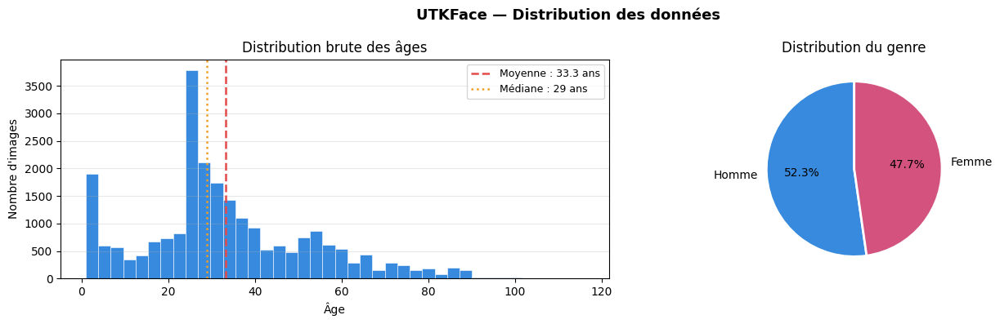

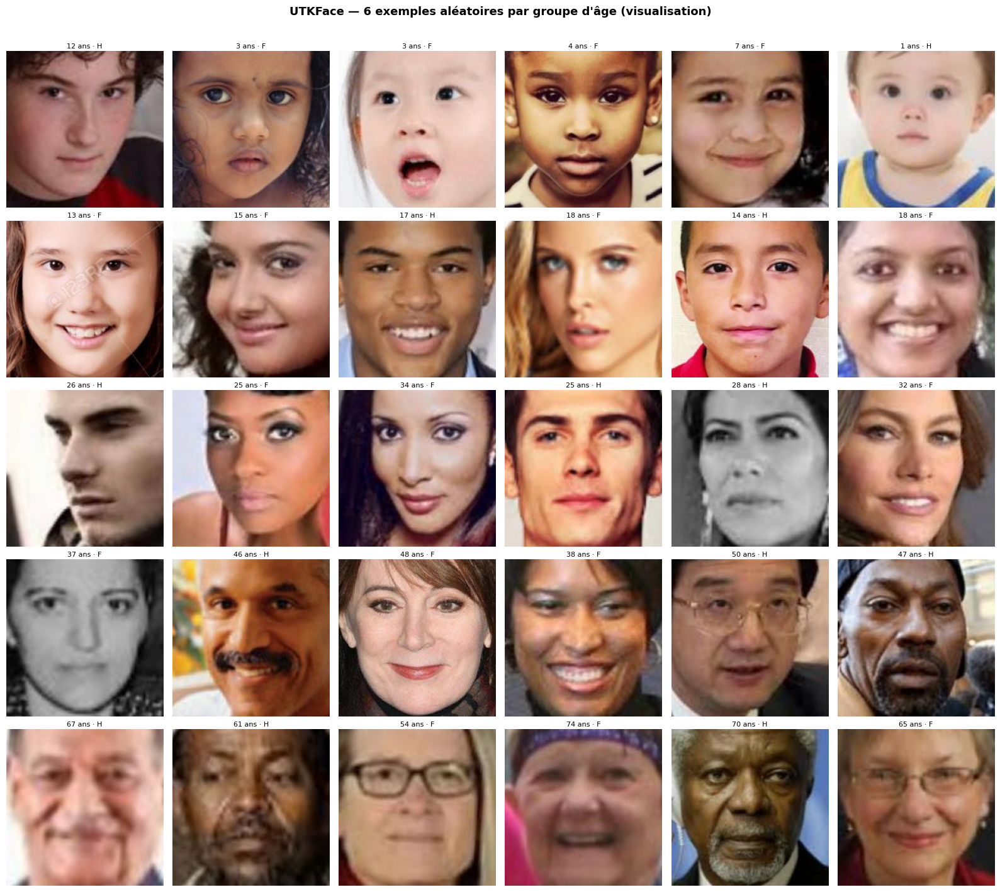


Exploration UTKFace terminée.
DataFrame shape : (23708, 5)
Colonnes : ['filename', 'filepath', 'age', 'gender', 'source']

→ Âge utilisé en RÉGRESSION (valeur exacte 0-116)
→ Métrique : MAE (erreur moyenne en années)


In [3]:
# ==============================
# CHEMIN DATASET
# ==============================
UTKFace_gender_age_PATH = "/kaggle/input/datasets/jangedoo/utkface-new/utkface_aligned_cropped/UTKFace"

if not os.path.exists(UTKFace_gender_age_PATH):
    raise FileNotFoundError(f"Chemin introuvable : {UTKFace_gender_age_PATH}\n"
                            f"Contenu disponible : {os.listdir('/kaggle/input/')}")

records = []
errors  = []

# ==============================
# PARSING DES FICHIERS
# ==============================
for fname in os.listdir(UTKFace_gender_age_PATH):
    if not fname.endswith(".jpg"):
        continue

    parts = fname.split("_")
    if len(parts) < 3:
        errors.append(fname)
        continue

    try:
        age    = int(parts[0])
        gender = int(parts[1])

        if age < 0 or age > 116:
            errors.append(fname)
            continue
        if gender not in [0, 1]:
            errors.append(fname)
            continue

        records.append({
            "filename" : fname,
            "filepath" : os.path.join(UTKFace_gender_age_PATH, fname),
            "age"      : age,       # ← âge exact conservé
            "gender"   : gender,
            "source"   : "utkface",
        })

    except (ValueError, IndexError):
        errors.append(fname)

df = pd.DataFrame(records)

gender_labels = {0: "Homme", 1: "Femme"}

# ==============================
# STATISTIQUES
# ==============================
print(f"Images valides : {len(df)}")
print(f"Images erreurs : {len(errors)}")

print(f"\n{df[['filename','age','gender']].head(6)}")

print("=" * 42)
print("  STATISTIQUES GÉNÉRALES — UTKFace")
print("=" * 42)
print(f"\nTotal images  : {len(df)}")
print(f"Âge min       : {df['age'].min()} ans")
print(f"Âge max       : {df['age'].max()} ans")
print(f"Âge moyen     : {df['age'].mean():.1f} ans")
print(f"Âge médian    : {int(df['age'].median())} ans")
print(f"Écart-type    : {df['age'].std():.1f} ans")

print(f"\n{'─'*42}")
print(f"  GENRE")
print(f"{'─'*42}")

genre_counts = df["gender"].value_counts().sort_index()
total = len(df)

for g in [0, 1]:
    count = genre_counts[g]
    pct   = count / total * 100
    bar   = "█" * int(pct / 2)
    print(f"  {gender_labels[g]:<8} : {count:>5} imgs  ({pct:4.1f}%)  {bar}")

ratio = genre_counts[1] / genre_counts[0]
if 0.9 <= ratio <= 1.1:
    print("\n  Verdict : dataset bien équilibré")
else:
    print(f"\n  Verdict : léger déséquilibre (ratio F/H = {ratio:.2f})")
    print("  Action  : utiliser class_weight dans la loss genre")

# ==============================
# VISUALISATION DISTRIBUTION
# ==============================
fig, axes = plt.subplots(1, 2, figsize=(14, 4))  # ← 2 plots au lieu de 3
fig.suptitle("UTKFace — Distribution des données", fontsize=13, fontweight="bold")

# Plot 1 — histogramme brut des âges
axes[0].hist(df["age"], bins=40, color="#378ADD",
             edgecolor="white", linewidth=0.4)
axes[0].axvline(df["age"].mean(), color="#E24B4A", linestyle="--",
                linewidth=1.8, label=f"Moyenne : {df['age'].mean():.1f} ans")
axes[0].axvline(df["age"].median(), color="#EF9F27", linestyle=":",
                linewidth=1.8, label=f"Médiane : {int(df['age'].median())} ans")
axes[0].set_title("Distribution brute des âges")
axes[0].set_xlabel("Âge")
axes[0].set_ylabel("Nombre d'images")
axes[0].legend(fontsize=9)
axes[0].grid(axis="y", alpha=0.3)

# Plot 2 — genre
genre_counts_vals = [genre_counts.get(g, 0) for g in [0, 1]]
axes[1].pie(genre_counts_vals,
            labels=["Homme", "Femme"],
            autopct="%1.1f%%",
            colors=["#378ADD","#D4537E"],
            startangle=90,
            wedgeprops={"edgecolor":"white","linewidth":2})
axes[1].set_title("Distribution du genre")

plt.tight_layout()
plt.savefig("utk_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

# ==============================
# AFFICHAGE IMAGES ALÉATOIRES
# ── par tranche d'âge indicative (pour la visu uniquement)
# ── les tranches ne sont plus utilisées dans le modèle
# ==============================
age_bins   = [(0,12,"0-12","#5DCAA5"), (13,19,"13-19","#1D9E75"),
              (20,35,"20-35","#534AB7"), (36,50,"36-50","#EF9F27"),
              (51,116,"51+","#D85A30")]

fig, axes = plt.subplots(5, 6, figsize=(16, 14))
fig.suptitle("UTKFace — 6 exemples aléatoires par groupe d'âge (visualisation)",
             fontsize=13, fontweight="bold", y=1.01)

for row_idx, (age_min, age_max, label, color) in enumerate(age_bins):
    subset  = df[(df["age"] >= age_min) & (df["age"] <= age_max)]
    samples = subset.sample(min(6, len(subset)), random_state=row_idx * 7)

    for col_idx, (_, sample) in enumerate(samples.iterrows()):
        ax  = axes[row_idx][col_idx]
        img = mpimg.imread(sample["filepath"])
        ax.imshow(img)
        genre_str = "H" if sample["gender"] == 0 else "F"
        ax.set_title(f"{sample['age']} ans · {genre_str}", fontsize=8, pad=3)
        ax.axis("off")
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(3)
            spine.set_visible(True)

    axes[row_idx][0].set_ylabel(
        f"{label}",
        fontsize=10, rotation=0,
        labelpad=50, va="center", fontweight="bold"
    )

plt.tight_layout()
plt.savefig("utk_exemples.png", dpi=120, bbox_inches="tight")
plt.show()

print("\nExploration UTKFace terminée.")
print(f"DataFrame shape : {df.shape}")
print(f"Colonnes : {list(df.columns)}")
print(f"\n→ Âge utilisé en RÉGRESSION (valeur exacte 0-116)")
print(f"→ Métrique : MAE (erreur moyenne en années)")

## B. EDA IMDB-WIKI

Total entrées dans .mat : 460723

  RÉSULTAT FILTRAGE
  Images valides           : 171816
  Filtrées (face_score<1)  : 72947
  Filtrées (2 visages)     : 212942
  Filtrées (genre manquant): 2782
  Filtrées (âge invalide)  : 236
  Filtrées (fichier absent): 0

  STATISTIQUES — IMDB-Wiki

Total images valides : 171816
Âge min     : 0 ans
Âge max     : 99 ans
Âge moyen   : 36.9 ans
Âge médian  : 35 ans
Écart-type  : 13.0 ans

──────────────────────────────────────────────────
  GENRE
──────────────────────────────────────────────────
  Homme    :  93698 imgs  (54.5%)  ███████████████████████████
  Femme    :  78118 imgs  (45.5%)  ██████████████████████

  Verdict : déséquilibre (ratio F/H = 0.83)
  Action  : class_weight dans la loss genre

──────────────────────────────────────────────────
  COMPARAISON UTKFace vs IMDB-Wiki
──────────────────────────────────────────────────
  Métrique           UTKFace    IMDB-Wiki
  ────────────────────────────────────────
  Total images         23708  

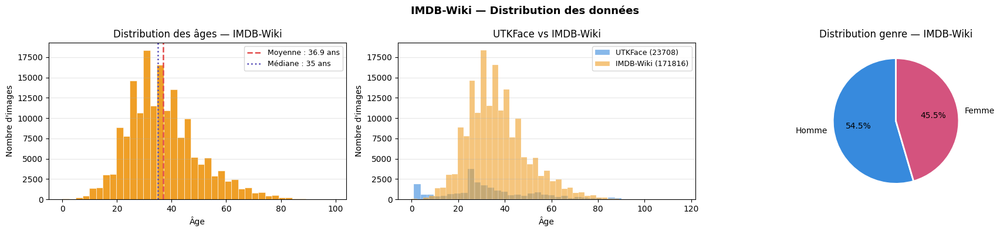

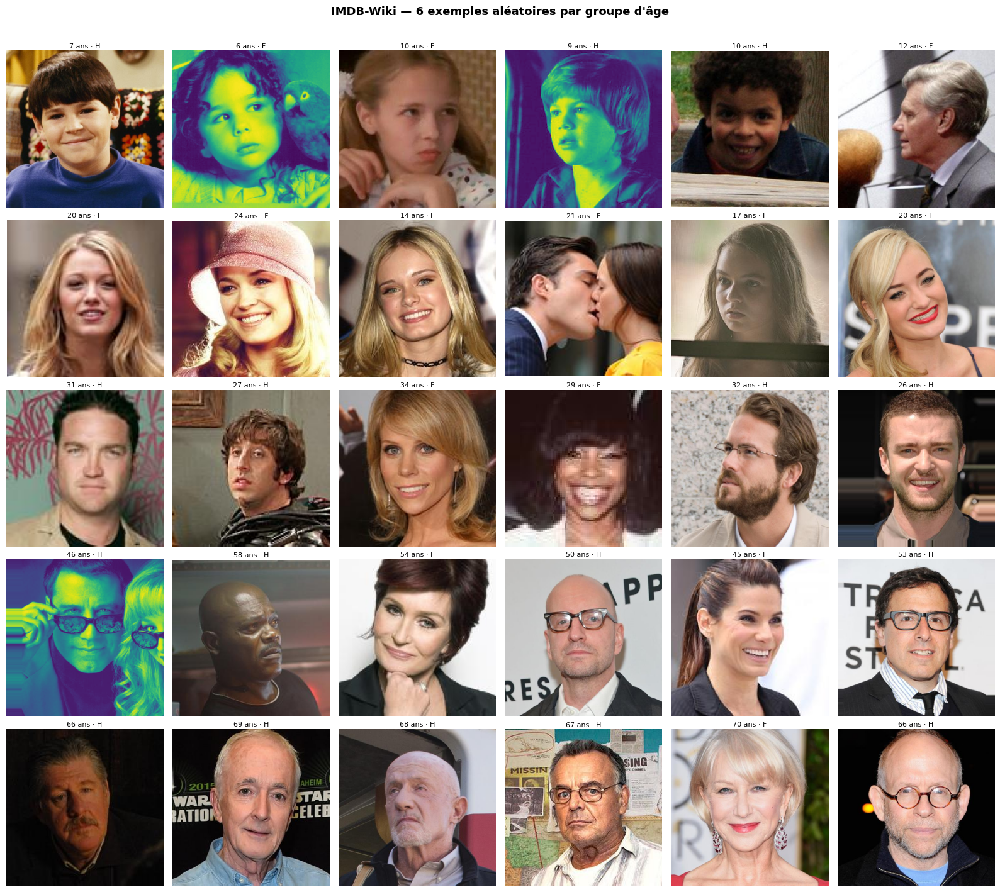


Exploration IMDB-Wiki terminée ✅
DataFrame : (171816, 4)
Colonnes  : ['filepath', 'age', 'gender', 'source']
→ Mapping genre : 0=Homme 1=Femme (aligné UTKFace)
→ Sauvegardé : /kaggle/working/imdb_clean.csv


In [4]:
# ==============================
# CHEMIN DATASET
# ==============================
IMDB_PATH = "/kaggle/input/datasets/abhikjha/imdb-wiki-faces-dataset/imdb_crop"

# ==============================
# LIRE LE FICHIER .MAT
# ==============================
mat  = loadmat(os.path.join(IMDB_PATH, "imdb.mat"))
imdb = mat["imdb"][0][0]

dob         = imdb["dob"].flatten()
photo_taken = imdb["photo_taken"].flatten()
full_path   = imdb["full_path"].flatten()
gender      = imdb["gender"].flatten()
face_score  = imdb["face_score"].flatten()
second_face = imdb["second_face_score"].flatten()

print(f"Total entrées dans .mat : {len(full_path)}")

# ==============================
# CALCULER L'ÂGE DEPUIS DOB
# ==============================
def matlab_datenum_to_year(datenum):
    """
    MATLAB datenum → année
    MATLAB compte les jours depuis le 01/01/0000
    1 an ≈ 365.25 jours
    """
    try:
        d = float(datenum)
        if d <= 0:
            return None
        year = int(d / 365.25)
        if 1900 <= year <= 2024:
            return year
        return None
    except:
        return None

# ==============================
# PARSING + FILTRAGE CORRIGÉ
# ==============================
records = []
n_no_face    = 0
n_two_faces  = 0
n_no_gender  = 0
n_bad_age    = 0
n_no_file    = 0

for i in range(len(full_path)):

    # Filtre 1 — score visage insuffisant
    fs = float(face_score[i])
    if np.isnan(fs) or fs < 1.0:
        n_no_face += 1
        continue

    # Filtre 2 — deuxième visage présent
    # NaN = pas de 2ème visage = BONNE image ← correction du bug
    sf = second_face[i]
    if not np.isnan(sf):
        n_two_faces += 1
        continue

    # Filtre 3 — genre valide
    g = gender[i]
    if np.isnan(g):
        n_no_gender += 1
        continue
    g = int(g)
    # IMDB : 0=Femme, 1=Homme → inverser pour UTKFace (0=Homme, 1=Femme)
    g_utk = 1 - g

    # Filtre 4 — âge valide
    birth_year = matlab_datenum_to_year(dob[i])
    year_taken = int(photo_taken[i])
    if birth_year is None:
        n_bad_age += 1
        continue
    age = year_taken - birth_year
    if age < 0 or age > 100:
        n_bad_age += 1
        continue

    # Filtre 5 — fichier existe
    path_str = str(full_path[i][0])
    filepath = os.path.join(IMDB_PATH, path_str)
    if not os.path.exists(filepath):
        n_no_file += 1
        continue

    records.append({
        "filepath" : filepath,
        "age"      : age,
        "gender"   : g_utk,
        "source"   : "imdb",
    })

df_imdb = pd.DataFrame(records)

print(f"\n{'='*50}")
print(f"  RÉSULTAT FILTRAGE")
print(f"{'='*50}")
print(f"  Images valides           : {len(df_imdb)}")
print(f"  Filtrées (face_score<1)  : {n_no_face}")
print(f"  Filtrées (2 visages)     : {n_two_faces}")
print(f"  Filtrées (genre manquant): {n_no_gender}")
print(f"  Filtrées (âge invalide)  : {n_bad_age}")
print(f"  Filtrées (fichier absent): {n_no_file}")

# ==============================
# STATISTIQUES
# ==============================
genre_counts_imdb = df_imdb["gender"].value_counts().sort_index()
total_imdb = len(df_imdb)
gender_labels = {0: "Homme", 1: "Femme"}

print(f"\n{'='*50}")
print(f"  STATISTIQUES — IMDB-Wiki")
print(f"{'='*50}")
print(f"\nTotal images valides : {total_imdb}")
print(f"Âge min     : {df_imdb['age'].min()} ans")
print(f"Âge max     : {df_imdb['age'].max()} ans")
print(f"Âge moyen   : {df_imdb['age'].mean():.1f} ans")
print(f"Âge médian  : {int(df_imdb['age'].median())} ans")
print(f"Écart-type  : {df_imdb['age'].std():.1f} ans")

print(f"\n{'─'*50}")
print(f"  GENRE")
print(f"{'─'*50}")
for g in [0, 1]:
    count = genre_counts_imdb.get(g, 0)
    pct   = count / total_imdb * 100
    bar   = "█" * int(pct / 2)
    print(f"  {gender_labels[g]:<8} : {count:>6} imgs  ({pct:4.1f}%)  {bar}")

# Déséquilibre genre
ratio = genre_counts_imdb.get(1, 0) / genre_counts_imdb.get(0, 1)
if 0.85 <= ratio <= 1.15:
    print("\n  Verdict : dataset bien équilibré")
else:
    print(f"\n  Verdict : déséquilibre (ratio F/H = {ratio:.2f})")
    print("  Action  : class_weight dans la loss genre")

print(f"\n{'─'*50}")
print(f"  COMPARAISON UTKFace vs IMDB-Wiki")
print(f"{'─'*50}")
print(f"  {'Métrique':<15} {'UTKFace':>10} {'IMDB-Wiki':>12}")
print(f"  {'─'*40}")
print(f"  {'Total images':<15} {len(df):>10} {total_imdb:>12}")
print(f"  {'Âge moyen':<15} {df['age'].mean():>9.1f}  {df_imdb['age'].mean():>11.1f}")
print(f"  {'Âge médian':<15} {int(df['age'].median()):>10} {int(df_imdb['age'].median()):>12}")
print(f"  {'Âge min':<15} {df['age'].min():>10} {df_imdb['age'].min():>12}")
print(f"  {'Âge max':<15} {df['age'].max():>10} {df_imdb['age'].max():>12}")

# ==============================
# VISUALISATION
# ==============================
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
fig.suptitle("IMDB-Wiki — Distribution des données", fontsize=13, fontweight="bold")

# Histogramme âges IMDB
axes[0].hist(df_imdb["age"], bins=40, color="#EF9F27",
             edgecolor="white", linewidth=0.4)
axes[0].axvline(df_imdb["age"].mean(), color="#E24B4A", linestyle="--",
                linewidth=1.8, label=f"Moyenne : {df_imdb['age'].mean():.1f} ans")
axes[0].axvline(df_imdb["age"].median(), color="#534AB7", linestyle=":",
                linewidth=1.8, label=f"Médiane : {int(df_imdb['age'].median())} ans")
axes[0].set_title("Distribution des âges — IMDB-Wiki")
axes[0].set_xlabel("Âge")
axes[0].set_ylabel("Nombre d'images")
axes[0].legend(fontsize=9)
axes[0].grid(axis="y", alpha=0.3)

# Comparaison UTKFace vs IMDB
axes[1].hist(df["age"],      bins=40, color="#378ADD", alpha=0.6,
             edgecolor="white", linewidth=0.3, label=f"UTKFace ({len(df)})")
axes[1].hist(df_imdb["age"], bins=40, color="#EF9F27", alpha=0.6,
             edgecolor="white", linewidth=0.3, label=f"IMDB-Wiki ({total_imdb})")
axes[1].set_title("UTKFace vs IMDB-Wiki")
axes[1].set_xlabel("Âge")
axes[1].set_ylabel("Nombre d'images")
axes[1].legend(fontsize=9)
axes[1].grid(axis="y", alpha=0.3)

# Genre IMDB
genre_vals = [genre_counts_imdb.get(g, 0) for g in [0, 1]]
axes[2].pie(genre_vals,
            labels=["Homme", "Femme"],
            autopct="%1.1f%%",
            colors=["#378ADD","#D4537E"],
            startangle=90,
            wedgeprops={"edgecolor":"white","linewidth":2})
axes[2].set_title("Distribution genre — IMDB-Wiki")

plt.tight_layout()
plt.savefig("/kaggle/working/imdb_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

# ==============================
# AFFICHAGE IMAGES ALÉATOIRES
# ==============================
age_bins = [(0,12,"0-12","#5DCAA5"),   (13,25,"13-25","#1D9E75"),
            (26,40,"26-40","#534AB7"), (41,60,"41-60","#EF9F27"),
            (61,100,"61+","#D85A30")]

fig, axes = plt.subplots(5, 6, figsize=(16, 14))
fig.suptitle("IMDB-Wiki — 6 exemples aléatoires par groupe d'âge",
             fontsize=13, fontweight="bold", y=1.01)

for row_idx, (age_min, age_max, label, color) in enumerate(age_bins):
    subset = df_imdb[(df_imdb["age"] >= age_min) & (df_imdb["age"] <= age_max)]
    if len(subset) == 0:
        continue
    samples = subset.sample(min(6, len(subset)), random_state=row_idx * 7)

    for col_idx, (_, sample) in enumerate(samples.iterrows()):
        ax = axes[row_idx][col_idx]
        try:
            img = mpimg.imread(sample["filepath"])
            ax.imshow(img)
            genre_str = "H" if sample["gender"] == 0 else "F"
            ax.set_title(f"{sample['age']} ans · {genre_str}", fontsize=8, pad=3)
        except:
            ax.set_title("erreur", fontsize=8)
        ax.axis("off")
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(3)
            spine.set_visible(True)

    axes[row_idx][0].set_ylabel(
        f"{label}", fontsize=10, rotation=0,
        labelpad=50, va="center", fontweight="bold"
    )

plt.tight_layout()
plt.savefig("/kaggle/working/imdb_exemples.png", dpi=120, bbox_inches="tight")
plt.show()

# Sauvegarder
df_imdb.to_csv("/kaggle/working/imdb_clean.csv", index=False)

print(f"\nExploration IMDB-Wiki terminée ✅")
print(f"DataFrame : {df_imdb.shape}")
print(f"Colonnes  : {list(df_imdb.columns)}")
print(f"→ Mapping genre : 0=Homme 1=Femme (aligné UTKFace)")
print(f"→ Sauvegardé : /kaggle/working/imdb_clean.csv")

## C. Fusion UTKFace + IMDB-Wiki + Split

UTKFace total : 23708 images
  Âge moyen  : 33.3 ans
  Âge médian : 29 ans

IMDB-Wiki total : 171816 images
  Âge moyen  : 36.9 ans
  Âge médian : 35 ans

  DATASET COMBINÉ TOTAL — ÂGE
  Total images  : 195524
  UTKFace       : 23708 (12.1%)
  IMDB-Wiki     : 171816 (87.9%)

  Âge moyen     : 36.5 ans
  Âge médian    : 35 ans
  Âge min       : 0 ans
  Âge max       : 116 ans

  Genre combiné :
  Homme    : 106089 imgs (54.3%)
  Femme    :  89435 imgs (45.7%)

  SPLITS FINAUX — ÂGE COMBINÉ
  Train : 136866 images (70.0%)
  Val   :  29329 images (15.0%)
  Test  :  29329 images (15.0%)

  Distribution âge par split :
  Train → mean=36.5 · median=35 · std=14.0
  Val → mean=36.6 · median=35 · std=14.1
  Test → mean=36.4 · median=35 · std=14.0


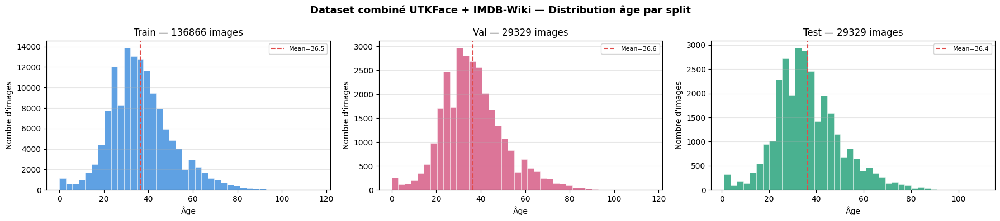

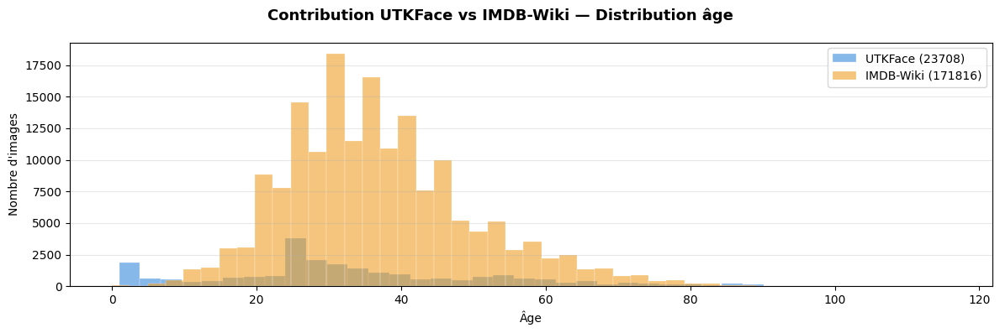


  FICHIERS SAUVEGARDÉS
  utk_train.csv : 136866 images
  utk_val.csv   :  29329 images
  utk_test.csv  :  29329 images

  Sources dans le dataset final :
  utkface      :  23708 images (12.1%)
  imdb         : 171816 images (87.9%)

Dataset âge combiné prêt ✅
→ Ces CSV remplacent les anciens utk_train/val/test.csv
→ UTKFaceDataset lit toujours 'age' + 'gender' → aucun changement


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# ==============================
# ÉTAPE 1 — PRÉPARER UTKFACE
# (df déjà en mémoire depuis EDA UTKFace)
# ==============================
df_utk_all = df[["filepath", "age", "gender", "source"]].copy()

print(f"UTKFace total : {len(df_utk_all)} images")
print(f"  Âge moyen  : {df_utk_all['age'].mean():.1f} ans")
print(f"  Âge médian : {int(df_utk_all['age'].median())} ans")

# ==============================
# ÉTAPE 2 — PRÉPARER IMDB-WIKI
# (df_imdb déjà en mémoire depuis EDA IMDB)
# ==============================
df_imdb_all = df_imdb[["filepath", "age", "gender", "source"]].copy()

print(f"\nIMDB-Wiki total : {len(df_imdb_all)} images")
print(f"  Âge moyen  : {df_imdb_all['age'].mean():.1f} ans")
print(f"  Âge médian : {int(df_imdb_all['age'].median())} ans")

# ==============================
# ÉTAPE 3 — COMBINER LES DEUX
# ==============================
df_age_combined = pd.concat([df_utk_all, df_imdb_all], ignore_index=True)
df_age_combined = df_age_combined.sample(frac=1, random_state=42).reset_index(drop=True)

total = len(df_age_combined)

print(f"\n{'='*50}")
print(f"  DATASET COMBINÉ TOTAL — ÂGE")
print(f"{'='*50}")
print(f"  Total images  : {total}")
print(f"  UTKFace       : {len(df_utk_all)} ({len(df_utk_all)/total*100:.1f}%)")
print(f"  IMDB-Wiki     : {len(df_imdb_all)} ({len(df_imdb_all)/total*100:.1f}%)")
print(f"\n  Âge moyen     : {df_age_combined['age'].mean():.1f} ans")
print(f"  Âge médian    : {int(df_age_combined['age'].median())} ans")
print(f"  Âge min       : {df_age_combined['age'].min()} ans")
print(f"  Âge max       : {df_age_combined['age'].max()} ans")

# Genre combiné
print(f"\n  Genre combiné :")
for g in [0, 1]:
    count = (df_age_combined["gender"] == g).sum()
    pct   = count / total * 100
    print(f"  {gender_labels[g]:<8} : {count:>6} imgs ({pct:.1f}%)")

# ==============================
# ÉTAPE 4 — SPLIT 70 / 15 / 15
# ==============================
df_train_utk, df_temp = train_test_split(
    df_age_combined,
    test_size    = 0.30,
    random_state = 42,
    stratify     = df_age_combined["gender"]
)
df_val_utk, df_test_utk = train_test_split(
    df_temp,
    test_size    = 0.50,
    random_state = 42,
    stratify     = df_temp["gender"]
)

print(f"\n{'='*50}")
print(f"  SPLITS FINAUX — ÂGE COMBINÉ")
print(f"{'='*50}")
print(f"  Train : {len(df_train_utk):>6} images ({len(df_train_utk)/total*100:.1f}%)")
print(f"  Val   : {len(df_val_utk):>6} images ({len(df_val_utk)/total*100:.1f}%)")
print(f"  Test  : {len(df_test_utk):>6} images ({len(df_test_utk)/total*100:.1f}%)")

# Vérification distribution âge par split
print(f"\n  Distribution âge par split :")
for name, split_df in [("Train", df_train_utk), ("Val", df_val_utk), ("Test", df_test_utk)]:
    print(f"  {name} → mean={split_df['age'].mean():.1f} · "
          f"median={int(split_df['age'].median())} · "
          f"std={split_df['age'].std():.1f}")

# ==============================
# VISUALISATION
# ==============================
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
fig.suptitle("Dataset combiné UTKFace + IMDB-Wiki — Distribution âge par split",
             fontsize=13, fontweight="bold")

colors = ["#378ADD", "#D4537E", "#1D9E75"]

for ax, (split_df, split_name, color) in zip(axes, [
    (df_train_utk, "Train", "#378ADD"),
    (df_val_utk,   "Val",   "#D4537E"),
    (df_test_utk,  "Test",  "#1D9E75"),
]):
    ax.hist(split_df["age"], bins=40, color=color,
            edgecolor="white", linewidth=0.4, alpha=0.8)
    ax.axvline(split_df["age"].mean(), color="#E24B4A", linestyle="--",
               linewidth=1.5, label=f"Mean={split_df['age'].mean():.1f}")
    ax.set_title(f"{split_name} — {len(split_df)} images")
    ax.set_xlabel("Âge")
    ax.set_ylabel("Nombre d'images")
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/age_combined_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

# Contribution UTKFace vs IMDB
fig, ax = plt.subplots(figsize=(12, 4))
fig.suptitle("Contribution UTKFace vs IMDB-Wiki — Distribution âge",
             fontsize=13, fontweight="bold")

ax.hist(df_utk_all["age"],  bins=40, color="#378ADD", alpha=0.6,
        edgecolor="white", linewidth=0.3, label=f"UTKFace ({len(df_utk_all)})")
ax.hist(df_imdb_all["age"], bins=40, color="#EF9F27", alpha=0.6,
        edgecolor="white", linewidth=0.3, label=f"IMDB-Wiki ({len(df_imdb_all)})")
ax.set_xlabel("Âge")
ax.set_ylabel("Nombre d'images")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/utk_vs_imdb_contribution.png", dpi=120, bbox_inches="tight")
plt.show()

# ==============================
# ÉTAPE 5 — SAUVEGARDER
# ==============================
df_train_utk.to_csv("/kaggle/working/utk_train.csv", index=False)
df_val_utk.to_csv("/kaggle/working/utk_val.csv",     index=False)
df_test_utk.to_csv("/kaggle/working/utk_test.csv",   index=False)

print(f"\n{'='*50}")
print(f"  FICHIERS SAUVEGARDÉS")
print(f"{'='*50}")
print(f"  utk_train.csv : {len(df_train_utk):>6} images")
print(f"  utk_val.csv   : {len(df_val_utk):>6} images")
print(f"  utk_test.csv  : {len(df_test_utk):>6} images")
print(f"\n  Sources dans le dataset final :")
for src in ["utkface", "imdb"]:
    n   = (df_age_combined["source"] == src).sum()
    pct = n / total * 100
    print(f"  {src:<12} : {n:>6} images ({pct:.1f}%)")
print(f"\nDataset âge combiné prêt ✅")
print(f"→ Ces CSV remplacent les anciens utk_train/val/test.csv")
print(f"→ UTKFaceDataset lit toujours 'age' + 'gender' → aucun changement")

## 3.2. Dataset pour "emotions" 

## A. EDA RAF-DB

Images valides : 15339

Aperçu :
                  filename  emotion_class emotion_label  split
0  train_00110_aligned.jpg              0      Surprise  train
1  train_01000_aligned.jpg              0      Surprise  train
2  train_06497_aligned.jpg              0      Surprise  train
3  train_00509_aligned.jpg              0      Surprise  train
4  train_08329_aligned.jpg              0      Surprise  train
5  train_04289_aligned.jpg              0      Surprise  train
6  train_08257_aligned.jpg              0      Surprise  train
7  train_02864_aligned.jpg              0      Surprise  train

  STATISTIQUES — RAF-DB

Total images : 15339
  Train      : 12271 (80.0%)
  Test       : 3068  (20.0%)

─────────────────────────────────────────────
  DISTRIBUTION ÉMOTIONS (train)
─────────────────────────────────────────────
  Surprise     :  1290 imgs  (10.5%)  ███████████████
  Peur         :   281 imgs  ( 2.3%)  ███
  Dégoût       :   717 imgs  ( 5.8%)  ████████
  Joie         :  4772 imgs

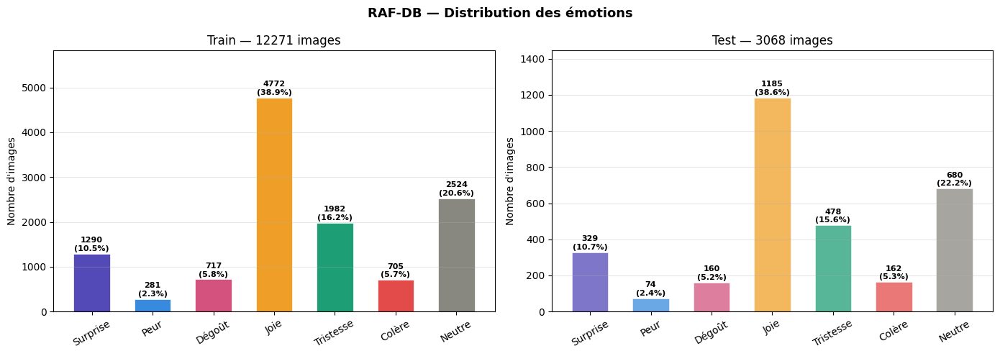

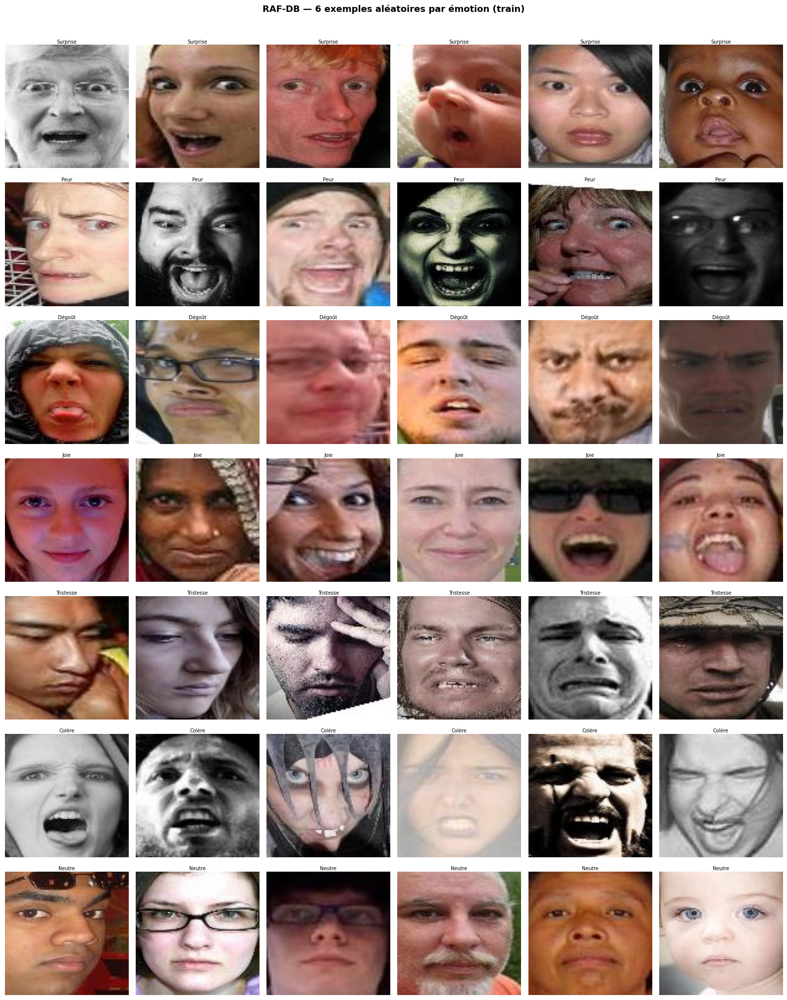


  RÉSUMÉ FINAL — RAF-DB

  Total images  : 15339
  Train         : 12271
  Test          : 3068
  Colonnes      : ['filename', 'filepath', 'emotion_class', 'emotion_label', 'split', 'source']

  ✅ rafdb_clean.csv sauvegardé
  → Pas de split ici
  → Le split 70/15/15 sera fait après combinaison avec AffectNet

Exploration RAF-DB terminée.


In [6]:
# ==============================
# CHEMIN DATASET
# ==============================
RAFDB_EMOTION_PATH = "/kaggle/input/datasets/shuvoalok/raf-db-dataset"

# ==============================
# MAPPING OFFICIEL RAF-DB
# ==============================
emotion_map = {
    "1": "Surprise",
    "2": "Peur",
    "3": "Dégoût",
    "4": "Joie",
    "5": "Tristesse",
    "6": "Colère",
    "7": "Neutre"
}

emotion_colors = {
    "1": "#534AB7",
    "2": "#378ADD",
    "3": "#D4537E",
    "4": "#EF9F27",
    "5": "#1D9E75",
    "6": "#E24B4A",
    "7": "#888780",
}

# Classes numériques alignées sur le système final
# Surprise=0, Peur=1, Dégoût=2, Joie=3, Tristesse=4, Colère=5, Neutre=6
emotion_class_map = {
    "1": 0,  # Surprise
    "2": 1,  # Peur
    "3": 2,  # Dégoût
    "4": 3,  # Joie
    "5": 4,  # Tristesse
    "6": 5,  # Colère
    "7": 6,  # Neutre
}

# ==============================
# PARSING TRAIN + TEST
# ==============================
records = []

for split in ["train", "test"]:
    split_path = os.path.join(RAFDB_EMOTION_PATH, "DATASET", split)

    for folder in sorted(os.listdir(split_path)):
        folder_path = os.path.join(split_path, folder)

        if not os.path.isdir(folder_path):
            continue
        if folder not in emotion_map:
            continue

        for fname in os.listdir(folder_path):
            if not fname.lower().endswith((".jpg", ".png")):
                continue

            records.append({
                "filename"      : fname,
                "filepath"      : os.path.join(folder_path, fname),
                "emotion_class" : emotion_class_map[folder],
                "emotion_label" : emotion_map[folder],
                "split"         : split,
                "source"        : "rafdb",
            })

df_raf = pd.DataFrame(records)

print(f"Images valides : {len(df_raf)}")
print(f"\nAperçu :")
print(df_raf[["filename", "emotion_class", "emotion_label", "split"]].head(8))

# ==============================
# STATISTIQUES
# ==============================
print(f"\n{'='*45}")
print("  STATISTIQUES — RAF-DB")
print(f"{'='*45}")

total    = len(df_raf)
df_train = df_raf[df_raf["split"] == "train"]
df_test  = df_raf[df_raf["split"] == "test"]

print(f"\nTotal images : {total}")
print(f"  Train      : {len(df_train)} ({len(df_train)/total*100:.1f}%)")
print(f"  Test       : {len(df_test)}  ({len(df_test)/total*100:.1f}%)")

print(f"\n{'─'*45}")
print(f"  DISTRIBUTION ÉMOTIONS (train)")
print(f"{'─'*45}")

train_counts = df_train["emotion_label"].value_counts()
max_count    = train_counts.max()
min_count    = train_counts.min()

for folder_id in ["1","2","3","4","5","6","7"]:
    label = emotion_map[folder_id]
    count = train_counts.get(label, 0)
    pct   = count / len(df_train) * 100
    bar   = "█" * int(pct * 1.5)
    print(f"  {label:<12} : {count:>5} imgs  ({pct:4.1f}%)  {bar}")

print(f"\n  Déséquilibre : x{max_count/min_count:.1f} "
      f"({train_counts.idxmax()} vs {train_counts.idxmin()})")
print(f"  → Sera corrigé par class_weight après combinaison")

# ==============================
# VISUALISATION DISTRIBUTION
# ==============================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("RAF-DB — Distribution des émotions", fontsize=13, fontweight="bold")

labels_ordered = [emotion_map[str(i)] for i in range(1, 8)]
colors_ordered = [emotion_colors[str(i)] for i in range(1, 8)]

# Train
counts_train = [train_counts.get(emotion_map[str(i)], 0) for i in range(1, 8)]
bars = axes[0].bar(labels_ordered, counts_train,
                   color=colors_ordered, edgecolor="white",
                   linewidth=0.5, width=0.6)
for bar, count in zip(bars, counts_train):
    pct = count / len(df_train) * 100
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 30,
                 f"{count}\n({pct:.1f}%)",
                 ha="center", va="bottom", fontsize=8, fontweight="bold")
axes[0].set_title(f"Train — {len(df_train)} images")
axes[0].set_ylabel("Nombre d'images")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_ylim(0, max(counts_train) * 1.22)
axes[0].grid(axis="y", alpha=0.3)

# Test
counts_test = [len(df_test[df_test["emotion_label"] == emotion_map[str(i)]])
               for i in range(1, 8)]
bars2 = axes[1].bar(labels_ordered, counts_test,
                    color=colors_ordered, edgecolor="white",
                    linewidth=0.5, width=0.6, alpha=0.75)
for bar, count in zip(bars2, counts_test):
    pct = count / len(df_test) * 100
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 8,
                 f"{count}\n({pct:.1f}%)",
                 ha="center", va="bottom", fontsize=8, fontweight="bold")
axes[1].set_title(f"Test — {len(df_test)} images")
axes[1].set_ylabel("Nombre d'images")
axes[1].tick_params(axis="x", rotation=30)
axes[1].set_ylim(0, max(counts_test) * 1.22)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("rafdb_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

# ==============================
# AFFICHAGE IMAGES ALÉATOIRES
# ==============================
fig, axes = plt.subplots(7, 6, figsize=(16, 20))
fig.suptitle("RAF-DB — 6 exemples aléatoires par émotion (train)",
             fontsize=13, fontweight="bold", y=1.01)

for row_idx, folder_id in enumerate(["1","2","3","4","5","6","7"]):
    emotion_name  = emotion_map[folder_id]
    emotion_color = emotion_colors[folder_id]

    subset  = df_train[df_train["emotion_label"] == emotion_name]
    samples = subset.sample(min(6, len(subset)), random_state=row_idx * 5)

    for col_idx, (_, sample) in enumerate(samples.iterrows()):
        ax  = axes[row_idx][col_idx]
        img = mpimg.imread(sample["filepath"])
        ax.imshow(img)
        ax.set_title(emotion_name, fontsize=7, pad=2)
        ax.axis("off")
        for spine in ax.spines.values():
            spine.set_edgecolor(emotion_color)
            spine.set_linewidth(3)
            spine.set_visible(True)

    axes[row_idx][0].set_ylabel(
        f"{emotion_name}\n({len(subset)} imgs)",
        fontsize=9, rotation=0,
        labelpad=75, va="center", fontweight="bold"
    )

plt.tight_layout()
plt.savefig("rafdb_exemples.png", dpi=120, bbox_inches="tight")
plt.show()

# ==============================
# SAUVEGARDER RAF-DB COMPLET
# (sans split — sera combiné avec AffectNet)
# ==============================
df_raf.to_csv("/kaggle/working/rafdb_clean.csv", index=False)

print(f"\n{'='*45}")
print("  RÉSUMÉ FINAL — RAF-DB")
print(f"{'='*45}")
print(f"\n  Total images  : {total}")
print(f"  Train         : {len(df_train)}")
print(f"  Test          : {len(df_test)}")
print(f"  Colonnes      : {list(df_raf.columns)}")
print(f"\n  ✅ rafdb_clean.csv sauvegardé")
print(f"  → Pas de split ici")
print(f"  → Le split 70/15/15 sera fait après combinaison avec AffectNet")
print(f"\nExploration RAF-DB terminée.")

## B. EDA AffectNet

Images valides : 27755

Aperçu :
           filename  emotion_class emotion_label  split
0  image0034802.jpg              0      Surprise  train
1  image0031111.jpg              0      Surprise  train
2  image0033666.jpg              0      Surprise  train
3  image0024358.jpg              0      Surprise  train
4  image0034220.jpg              0      Surprise  train
5  image0031027.jpg              0      Surprise  train
6  image0034149.jpg              0      Surprise  train
7  image0028489.jpg              0      Surprise  train

  STATISTIQUES — AffectNet

Total images  : 27755
  Train       : 14549 (52.4%)
  Test        : 13206  (47.6%)

──────────────────────────────────────────────────
  DISTRIBUTION ÉMOTIONS (train)
──────────────────────────────────────────────────
  Surprise     :  2119 imgs  (14.6%)  █████████████████████
  Peur         :  1512 imgs  (10.4%)  ███████████████
  Dégoût       :  1229 imgs  ( 8.4%)  ████████████
  Joie         :  2340 imgs  (16.1%)  █████████████

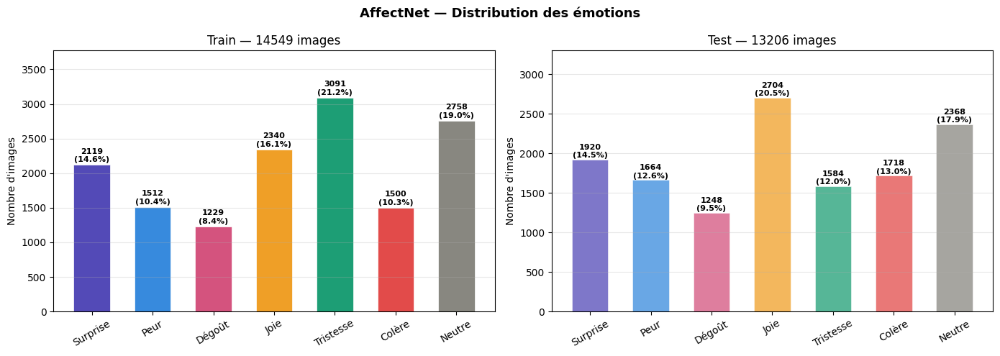

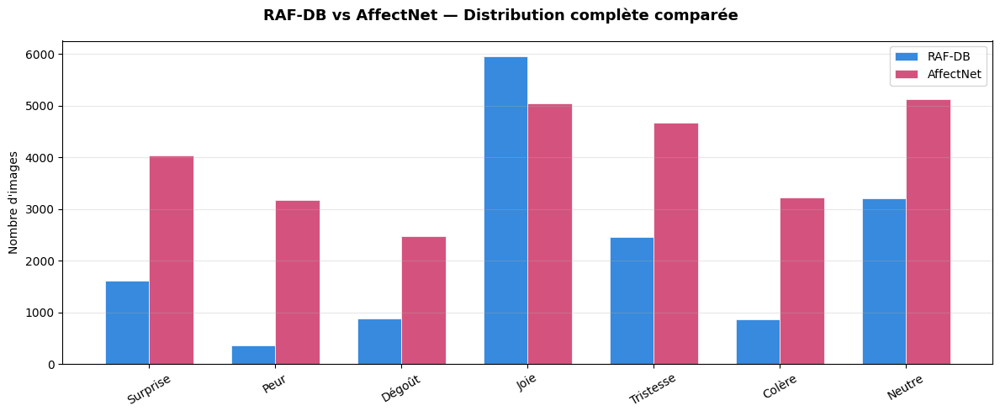

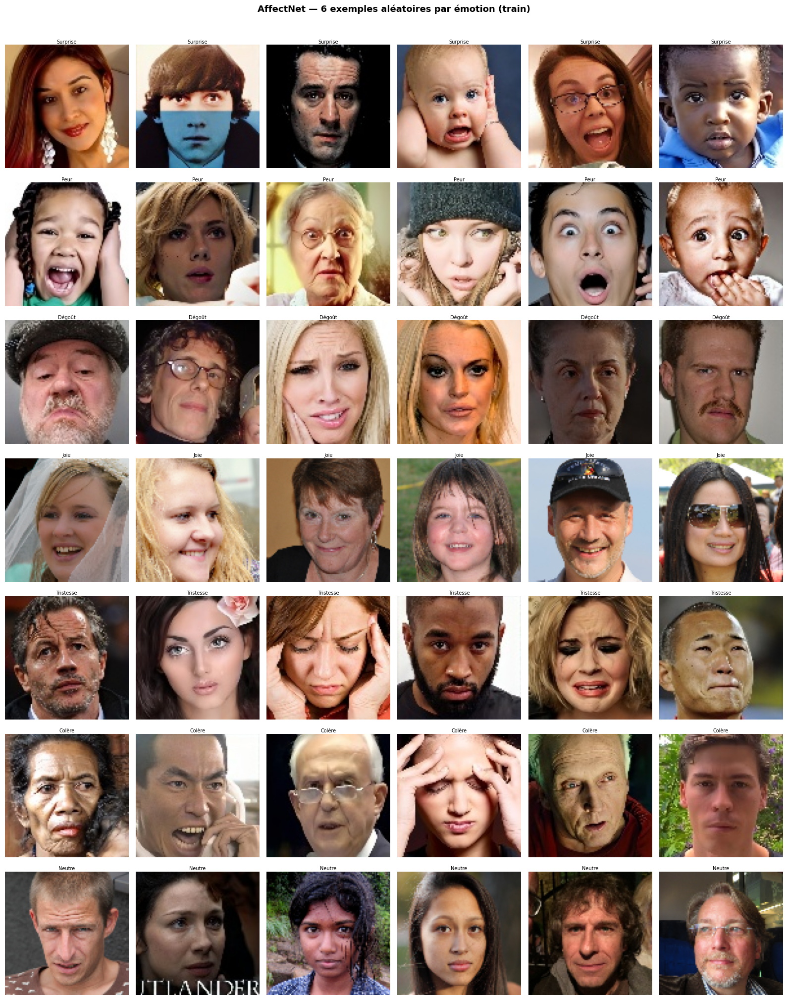


  RÉSUMÉ FINAL — AffectNet

  Total images  : 27755
  Train         : 14549
  Test          : 13206
  Colonnes      : ['filename', 'filepath', 'emotion_class', 'emotion_label', 'split', 'source']

  ✅ affectnet_clean.csv sauvegardé


In [7]:
# ==============================
# CHEMINS
# ==============================
AFFECTNET_PATH = "/kaggle/input/datasets/mstjebashazida/affectnet/archive (3)"
TRAIN_PATH     = os.path.join(AFFECTNET_PATH, "Train")
TEST_PATH      = os.path.join(AFFECTNET_PATH, "Test")

# ==============================
# MAPPING LABELS → CLASSES
# (aligné sur RAF-DB)
# ==============================
affect_emotion_map = {
    "surprise" : 0,
    "fear"     : 1,
    "disgust"  : 2,
    "happy"    : 3,
    "sad"      : 4,
    "anger"    : 5,
    "neutral"  : 6,
}

emotion_labels = {
    0: "Surprise",
    1: "Peur",
    2: "Dégoût",
    3: "Joie",
    4: "Tristesse",
    5: "Colère",
    6: "Neutre"
}

emotion_colors = {
    0: "#534AB7",
    1: "#378ADD",
    2: "#D4537E",
    3: "#EF9F27",
    4: "#1D9E75",
    5: "#E24B4A",
    6: "#888780",
}

# ==============================
# PARSING TRAIN + TEST
# ==============================
records = []

for split in ["Train", "Test"]:
    split_path = os.path.join(AFFECTNET_PATH, split)

    for folder in os.listdir(split_path):
        folder_path = os.path.join(split_path, folder)

        if not os.path.isdir(folder_path):
            continue

        folder_lower = folder.lower()

        # Ignorer contempt
        if folder_lower == "contempt":
            continue

        # Ignorer dossiers inconnus
        if folder_lower not in affect_emotion_map:
            print(f"  Dossier inconnu ignoré : {folder}")
            continue

        emotion_class = affect_emotion_map[folder_lower]

        for fname in os.listdir(folder_path):
            if not fname.lower().endswith((".jpg", ".png", ".jpeg")):
                continue

            records.append({
                "filename"      : fname,
                "filepath"      : os.path.join(folder_path, fname),
                "emotion_class" : emotion_class,
                "emotion_label" : emotion_labels[emotion_class],
                "split"         : split.lower(),
                "source"        : "affectnet",
            })

df_affect = pd.DataFrame(records)

print(f"Images valides : {len(df_affect)}")
print(f"\nAperçu :")
print(df_affect[["filename", "emotion_class", "emotion_label", "split"]].head(8))

# ==============================
# STATISTIQUES
# ==============================
print(f"\n{'='*50}")
print("  STATISTIQUES — AffectNet")
print(f"{'='*50}")

total       = len(df_affect)
df_train_af = df_affect[df_affect["split"] == "train"]
df_test_af  = df_affect[df_affect["split"] == "test"]

print(f"\nTotal images  : {total}")
print(f"  Train       : {len(df_train_af)} ({len(df_train_af)/total*100:.1f}%)")
print(f"  Test        : {len(df_test_af)}  ({len(df_test_af)/total*100:.1f}%)")

print(f"\n{'─'*50}")
print(f"  DISTRIBUTION ÉMOTIONS (train)")
print(f"{'─'*50}")

train_counts_af = df_train_af["emotion_label"].value_counts()
max_count       = train_counts_af.max()
min_count       = train_counts_af.min()

for cls in range(7):
    label = emotion_labels[cls]
    count = train_counts_af.get(label, 0)
    pct   = count / len(df_train_af) * 100
    bar   = "█" * int(pct * 1.5)
    print(f"  {label:<12} : {count:>5} imgs  ({pct:4.1f}%)  {bar}")

print(f"\n  Déséquilibre : x{max_count/min_count:.1f} "
      f"({train_counts_af.idxmax()} vs {train_counts_af.idxmin()})")
print(f"  → Sera corrigé par class_weight après combinaison")

# ==============================
# COMPARAISON RAF-DB vs AFFECTNET
# (utilise df_raf déjà en mémoire)
# ==============================
print(f"\n{'─'*50}")
print(f"  COMPARAISON RAF-DB vs AffectNet")
print(f"{'─'*50}")
print(f"  {'Émotion':<12} {'RAF-DB':>8} {'AffectNet':>10} {'Total':>8}")
print(f"  {'─'*42}")

raf_counts = df_raf["emotion_class"].value_counts().sort_index()

for cls in range(7):
    label     = emotion_labels[cls]
    raf_count = raf_counts.get(cls, 0)
    af_count  = (df_affect["emotion_class"] == cls).sum()
    total_cls = raf_count + af_count
    print(f"  {label:<12} {raf_count:>8} {af_count:>10} {total_cls:>8}")

print(f"\n  {'TOTAL':<12} {len(df_raf):>8} {len(df_affect):>10} {len(df_raf)+len(df_affect):>8}")

# ==============================
# VISUALISATION DISTRIBUTION
# ==============================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("AffectNet — Distribution des émotions", fontsize=13, fontweight="bold")

labels_ordered = [emotion_labels[i] for i in range(7)]
colors_ordered = [emotion_colors[i] for i in range(7)]

# Train
counts_train = [train_counts_af.get(emotion_labels[i], 0) for i in range(7)]
bars = axes[0].bar(labels_ordered, counts_train,
                   color=colors_ordered, edgecolor="white",
                   linewidth=0.5, width=0.6)
for bar, count in zip(bars, counts_train):
    pct = count / len(df_train_af) * 100
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 20,
                 f"{count}\n({pct:.1f}%)",
                 ha="center", va="bottom", fontsize=8, fontweight="bold")
axes[0].set_title(f"Train — {len(df_train_af)} images")
axes[0].set_ylabel("Nombre d'images")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_ylim(0, max(counts_train) * 1.22)
axes[0].grid(axis="y", alpha=0.3)

# Test
test_counts_af = df_test_af["emotion_label"].value_counts()
counts_test    = [test_counts_af.get(emotion_labels[i], 0) for i in range(7)]
bars2 = axes[1].bar(labels_ordered, counts_test,
                    color=colors_ordered, edgecolor="white",
                    linewidth=0.5, width=0.6, alpha=0.75)
for bar, count in zip(bars2, counts_test):
    pct = count / len(df_test_af) * 100 if len(df_test_af) > 0 else 0
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 5,
                 f"{count}\n({pct:.1f}%)",
                 ha="center", va="bottom", fontsize=8, fontweight="bold")
axes[1].set_title(f"Test — {len(df_test_af)} images")
axes[1].set_ylabel("Nombre d'images")
axes[1].tick_params(axis="x", rotation=30)
axes[1].set_ylim(0, max(counts_test) * 1.22 if counts_test else 1)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("affectnet_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

# ==============================
# VISUALISATION COMPARAISON
# RAF-DB vs AffectNet
# ==============================
import numpy as np

fig, ax = plt.subplots(figsize=(12, 5))
fig.suptitle("RAF-DB vs AffectNet — Distribution complète comparée",
             fontsize=13, fontweight="bold")

x     = np.arange(7)
width = 0.35

raf_vals = [raf_counts.get(i, 0) for i in range(7)]
af_vals  = [(df_affect["emotion_class"] == i).sum() for i in range(7)]

axes_bar1 = ax.bar(x - width/2, raf_vals, width,
                   label="RAF-DB", color="#378ADD",
                   edgecolor="white", linewidth=0.5)
axes_bar2 = ax.bar(x + width/2, af_vals, width,
                   label="AffectNet", color="#D4537E",
                   edgecolor="white", linewidth=0.5)

ax.set_xticks(x)
ax.set_xticklabels(labels_ordered, rotation=30)
ax.set_ylabel("Nombre d'images")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("rafdb_vs_affectnet.png", dpi=120, bbox_inches="tight")
plt.show()

# ==============================
# AFFICHAGE IMAGES ALÉATOIRES
# ==============================
fig, axes = plt.subplots(7, 6, figsize=(16, 20))
fig.suptitle("AffectNet — 6 exemples aléatoires par émotion (train)",
             fontsize=13, fontweight="bold", y=1.01)

for row_idx in range(7):
    emotion_name  = emotion_labels[row_idx]
    emotion_color = emotion_colors[row_idx]

    subset  = df_train_af[df_train_af["emotion_label"] == emotion_name]
    samples = subset.sample(min(6, len(subset)), random_state=row_idx * 5)

    for col_idx, (_, sample) in enumerate(samples.iterrows()):
        ax  = axes[row_idx][col_idx]
        img = mpimg.imread(sample["filepath"])
        ax.imshow(img)
        ax.set_title(emotion_name, fontsize=7, pad=2)
        ax.axis("off")
        for spine in ax.spines.values():
            spine.set_edgecolor(emotion_color)
            spine.set_linewidth(3)
            spine.set_visible(True)

    axes[row_idx][0].set_ylabel(
        f"{emotion_name}\n({len(subset)} imgs)",
        fontsize=9, rotation=0,
        labelpad=75, va="center", fontweight="bold"
    )

plt.tight_layout()
plt.savefig("affectnet_exemples.png", dpi=120, bbox_inches="tight")
plt.show()

# ==============================
# SAUVEGARDER AFFECTNET COMPLET
# (sans split — sera combiné avec RAF-DB)
# ==============================
df_affect.to_csv("/kaggle/working/affectnet_clean.csv", index=False)

print(f"\n{'='*50}")
print("  RÉSUMÉ FINAL — AffectNet")
print(f"{'='*50}")
print(f"\n  Total images  : {total}")
print(f"  Train         : {len(df_train_af)}")
print(f"  Test          : {len(df_test_af)}")
print(f"  Colonnes      : {list(df_affect.columns)}")
print(f"\n  ✅ affectnet_clean.csv sauvegardé")

## C. EDA CK+48 + Face Expression Recognition

In [8]:
# ── CHEMINS ──────────────────────────────────────────────
CKP_PATH  = "/kaggle/input/datasets/shawon10/ckplus/CK+48"
FER_PATH  = "/kaggle/input/datasets/jonathanoheix/face-expression-recognition-dataset/images/images"

# ── MAPPING VERS NOS CLASSES ─────────────────────────────
ckp_map = {
    "anger"    : 5,   # Colère
    "contempt" : None,
    "disgust"  : 2,   # Dégoût
    "fear"     : 1,   # Peur
    "happy"    : 3,   # Joie
    "sadness"  : 4,   # Tristesse
    "surprise" : 0,   # Surprise
}

fer_map = {
    "angry"   : 5,   # Colère
    "disgust" : 2,   # Dégoût
    "fear"    : 1,   # Peur
    "happy"   : 3,   # Joie
    "neutral" : 6,   # Neutre
    "sad"     : 4,   # Tristesse
    "surprise": 0,   # Surprise
}

emotion_labels_map = {
    0: "Surprise", 1: "Peur",      2: "Dégoût",
    3: "Joie",     4: "Tristesse", 5: "Colère", 6: "Neutre"
}

# ── COMPTER CK+48 ────────────────────────────────────────
print("=" * 55)
print("  CK+48")
print("=" * 55)

ckp_counts = {}
for folder in sorted(os.listdir(CKP_PATH)):
    folder_path = os.path.join(CKP_PATH, folder)
    if not os.path.isdir(folder_path):
        continue
    cls = ckp_map.get(folder.lower())
    n = len([f for f in os.listdir(folder_path)
             if f.lower().endswith((".jpg", ".png", ".jpeg"))])
    ckp_counts[folder] = {"cls": cls, "n": n}
    cls_label = emotion_labels_map[cls] if cls is not None else "IGNORÉ"
    bar = "█" * int(n / 5)
    print(f"  {folder:<12} → {cls_label:<12} : {n:>4} imgs  {bar}")

total_ckp = sum(v["n"] for v in ckp_counts.values())
print(f"\n  Total CK+48 : {total_ckp} images")

# ── COMPTER FER (train + test séparément) ────────────────
print("\n" + "=" * 55)
print("  Face Expression Recognition Dataset")
print("=" * 55)

fer_counts = {}
for split in ["train", "validation"]:
    split_path = os.path.join(FER_PATH, split)
    if not os.path.exists(split_path):
        print(f"  Split '{split}' non trouvé")
        continue

    print(f"\n  [{split}]")
    fer_counts[split] = {}

    for folder in sorted(os.listdir(split_path)):
        folder_path = os.path.join(split_path, folder)
        if not os.path.isdir(folder_path):
            continue
        cls = fer_map.get(folder.lower())
        n = len([f for f in os.listdir(folder_path)
                 if f.lower().endswith((".jpg", ".png", ".jpeg"))])
        fer_counts[split][folder] = {"cls": cls, "n": n}
        cls_label = emotion_labels_map[cls] if cls is not None else "IGNORÉ"
        bar = "█" * int(n / 100)
        print(f"    {folder:<12} → {cls_label:<12} : {n:>5} imgs  {bar}")

    total_split = sum(v["n"] for v in fer_counts[split].values())
    print(f"\n    Total {split} : {total_split} images")

  CK+48
  anger        → Colère       :  135 imgs  ███████████████████████████
  contempt     → IGNORÉ       :   54 imgs  ██████████
  disgust      → Dégoût       :  177 imgs  ███████████████████████████████████
  fear         → Peur         :   75 imgs  ███████████████
  happy        → Joie         :  207 imgs  █████████████████████████████████████████
  sadness      → Tristesse    :   84 imgs  ████████████████
  surprise     → Surprise     :  249 imgs  █████████████████████████████████████████████████

  Total CK+48 : 981 images

  Face Expression Recognition Dataset

  [train]
    angry        → Colère       :  3993 imgs  ███████████████████████████████████████
    disgust      → Dégoût       :   436 imgs  ████
    fear         → Peur         :  4103 imgs  █████████████████████████████████████████
    happy        → Joie         :  7164 imgs  ███████████████████████████████████████████████████████████████████████
    neutral      → Neutre       :  4982 imgs  ████████████████████████

## D. Combinaison des datasets + split 70% 15% 15%

Étape 1 → Préparer RAF-DB        (df_raf)

Étape 2 → Préparer AffectNet     (df_affect)

Étape 3 → Combiner RAF + Affect  (df_combined)

Étape 4 → Charger FER2013        (df_fer)        ← NOUVEAU

Étape 5 → Compléter les classes  (df_combined)   ← NOUVEAU

Étape 6 → Split 70/15/15

Étape 7 → Vérifier équilibre

Étape 8 → Sauvegarder

RAF-DB total : 15339 images
emotion_label
Joie         5957
Neutre       3204
Tristesse    2460
Surprise     1619
Dégoût        877
Colère        867
Peur          355
Name: count, dtype: int64

AffectNet total : 27755 images
emotion_label
Neutre       5126
Joie         5044
Tristesse    4675
Surprise     4039
Colère       3218
Peur         3176
Dégoût       2477
Name: count, dtype: int64

RAF-DB + AffectNet : 43094 images

FER2013 total chargé : 32298 images
emotion_label
Joie         8094
Neutre       5591
Tristesse    5424
Peur         4625
Colère       4486
Surprise     3587
Dégoût        491
Name: count, dtype: int64

  COMPLÉTION DEPUIS FER2013 (cible = 7000)
  Émotion        Actuel   Manque  Dispo FER   Ajouté
  ──────────────────────────────────────────────────
  Surprise         5658     1342       3587     1342
  Peur             3531     3469       4625     3469
  Dégoût           3354     3646        491      491  (tout FER2013 — pas assez)
  Joie            11001        — 

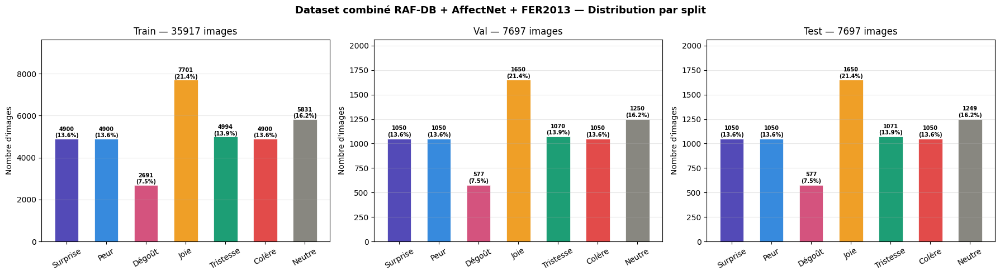

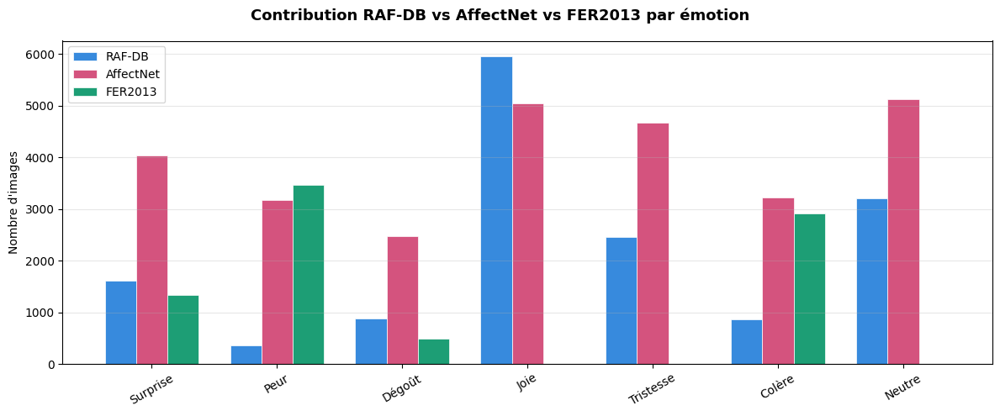


  FICHIERS SAUVEGARDÉS
  emotion_train_combined.csv :  35917 images
  emotion_val_combined.csv   :   7697 images
  emotion_test_combined.csv  :   7697 images

  Sources dans le dataset final :
  rafdb        :  15339 images (29.9%)
  affectnet    :  27755 images (54.1%)
  fer2013      :   8217 images (16.0%)

Dataset combiné prêt pour l'entraînement ✅


In [9]:
# ==============================
# ÉTAPE 1 — PRÉPARER RAF-DB
# ==============================
df_raf_all = df_raf[["filepath", "emotion_class", "emotion_label", "source"]].copy()

print(f"RAF-DB total : {len(df_raf_all)} images")
print(df_raf_all["emotion_label"].value_counts())

# ==============================
# ÉTAPE 2 — PRÉPARER AFFECTNET
# ==============================
df_affect_all = df_affect[["filepath", "emotion_class", "emotion_label", "source"]].copy()

print(f"\nAffectNet total : {len(df_affect_all)} images")
print(df_affect_all["emotion_label"].value_counts())

# ==============================
# ÉTAPE 3 — COMBINER RAF + AFFECTNET
# ==============================
df_combined = pd.concat([df_raf_all, df_affect_all], ignore_index=True)
df_combined = df_combined.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"\nRAF-DB + AffectNet : {len(df_combined)} images")

# ==============================
# ÉTAPE 4 — CHARGER FER2013
# ==============================
FER2013_PATH = "/kaggle/input/datasets/pankaj4321/fer-2013-facial-expression-dataset"

fer_emotion_map = {
    "angry"    : 5,
    "disgust"  : 2,
    "fear"     : 1,
    "happy"    : 3,
    "sad"      : 4,
    "surprise" : 0,
    "neutral"  : 6,
}

emotion_labels_map = {
    0: "Surprise", 1: "Peur",      2: "Dégoût",
    3: "Joie",     4: "Tristesse", 5: "Colère", 6: "Neutre"
}

records_fer = []
for split in ["train", "test"]:
    split_path = os.path.join(FER2013_PATH, split)
    if not os.path.exists(split_path):
        continue
    for folder in os.listdir(split_path):
        folder_path  = os.path.join(split_path, folder)
        folder_lower = folder.lower()
        if not os.path.isdir(folder_path) or folder_lower not in fer_emotion_map:
            continue
        emotion_class = fer_emotion_map[folder_lower]
        for fname in os.listdir(folder_path):
            if not fname.lower().endswith((".jpg", ".png", ".jpeg")):
                continue
            records_fer.append({
                "filepath"      : os.path.join(folder_path, fname),
                "emotion_class" : emotion_class,
                "emotion_label" : emotion_labels_map[emotion_class],
                "source"        : "fer2013",
            })

df_fer = pd.DataFrame(records_fer)
print(f"\nFER2013 total chargé : {len(df_fer)} images")
print(df_fer["emotion_label"].value_counts())

# ==============================
# ÉTAPE 5 — COMPLÉTER DEPUIS FER2013
# Cible : 7000 images par classe
# Dégoût → prendre tout FER2013 disponible
# ==============================
CIBLE       = 7000
records_add = []

print(f"\n{'='*55}")
print(f"  COMPLÉTION DEPUIS FER2013 (cible = {CIBLE})")
print(f"{'='*55}")
print(f"  {'Émotion':<12} {'Actuel':>8} {'Manque':>8} {'Dispo FER':>10} {'Ajouté':>8}")
print(f"  {'─'*50}")

for cls in range(7):
    label       = emotion_labels_map[cls]
    actuel      = (df_combined["emotion_class"] == cls).sum()
    fer_dispo   = df_fer[df_fer["emotion_class"] == cls]
    n_fer_dispo = len(fer_dispo)

    if actuel >= CIBLE:
        print(f"  {label:<12} {actuel:>8} {'—':>8} {n_fer_dispo:>10} {'0':>8}  (déjà ok)")
        continue

    manque = CIBLE - actuel

    if cls == 2:
        # Dégoût → prendre tout ce que FER2013 a (pas assez pour atteindre 7000)
        n_prendre = n_fer_dispo
        print(f"  {label:<12} {actuel:>8} {manque:>8} {n_fer_dispo:>10} {n_prendre:>8}  (tout FER2013 — pas assez)")
    else:
        n_prendre = min(manque, n_fer_dispo)
        print(f"  {label:<12} {actuel:>8} {manque:>8} {n_fer_dispo:>10} {n_prendre:>8}")

    if n_prendre > 0:
        records_add.append(fer_dispo.sample(n=n_prendre, random_state=42))

if records_add:
    df_fer_add  = pd.concat(records_add, ignore_index=True)
    df_combined = pd.concat([df_combined, df_fer_add], ignore_index=True)
    df_combined = df_combined.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"\n  Images ajoutées depuis FER2013 : {len(df_fer_add) if records_add else 0}")
print(f"  Total dataset : {len(df_combined)}")

# Distribution finale
total        = len(df_combined)
class_counts = df_combined["emotion_class"].value_counts().sort_index()

print(f"\n  Distribution finale :")
for cls in range(7):
    count = class_counts.get(cls, 0)
    pct   = count / total * 100
    bar   = "█" * int(pct * 1.5)
    print(f"  {emotion_labels_map[cls]:<12} : {count:>5} imgs  ({pct:4.1f}%)  {bar}")

max_c = class_counts.max()
min_c = class_counts.min()
print(f"\n  Déséquilibre : x{max_c/min_c:.1f}")
print(f"  → Dégoût reste sous-représenté mais class_weight compensera")

# ==============================
# ÉTAPE 6 — SPLIT 70 / 15 / 15
# ==============================
df_train_emotion, df_temp = train_test_split(
    df_combined,
    test_size    = 0.30,
    random_state = 42,
    stratify     = df_combined["emotion_class"]
)
df_val_emotion, df_test_emotion = train_test_split(
    df_temp,
    test_size    = 0.50,
    random_state = 42,
    stratify     = df_temp["emotion_class"]
)

print(f"\n{'='*50}")
print(f"  SPLITS FINAUX")
print(f"{'='*50}")
print(f"  Train : {len(df_train_emotion):>6} images ({len(df_train_emotion)/total*100:.1f}%)")
print(f"  Val   : {len(df_val_emotion):>6} images ({len(df_val_emotion)/total*100:.1f}%)")
print(f"  Test  : {len(df_test_emotion):>6} images ({len(df_test_emotion)/total*100:.1f}%)")

# ==============================
# ÉTAPE 7 — VÉRIFIER L'ÉQUILIBRE
# ==============================
emotion_colors_map = {
    0: "#534AB7", 1: "#378ADD", 2: "#D4537E",
    3: "#EF9F27", 4: "#1D9E75", 5: "#E24B4A", 6: "#888780"
}

print(f"\n{'─'*60}")
print(f"  DISTRIBUTION PAR SPLIT")
print(f"{'─'*60}")
print(f"  {'Émotion':<12} {'Train':>7} {'Val':>7} {'Test':>7}  {'Équilibré?':>10}")
print(f"  {'─'*54}")

for cls in range(7):
    label    = emotion_labels_map[cls]
    t_count  = (df_train_emotion["emotion_class"] == cls).sum()
    v_count  = (df_val_emotion["emotion_class"]   == cls).sum()
    te_count = (df_test_emotion["emotion_class"]  == cls).sum()
    t_pct    = t_count  / len(df_train_emotion) * 100
    v_pct    = v_count  / len(df_val_emotion)   * 100
    te_pct   = te_count / len(df_test_emotion)  * 100
    ok       = "✅" if abs(t_pct - v_pct) < 2 and abs(t_pct - te_pct) < 2 else "⚠️"
    print(f"  {label:<12} {t_count:>7} {v_count:>7} {te_count:>7}  {ok:>10}")

# ==============================
# VISUALISATION — Distribution par split
# ==============================
labels_ordered = [emotion_labels_map[i] for i in range(7)]
colors_ordered = [emotion_colors_map[i] for i in range(7)]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Dataset combiné RAF-DB + AffectNet + FER2013 — Distribution par split",
             fontsize=13, fontweight="bold")

for ax, (split_df, split_name) in zip(axes, [
    (df_train_emotion, "Train"),
    (df_val_emotion,   "Val"),
    (df_test_emotion,  "Test"),
]):
    counts = [(split_df["emotion_class"] == cls).sum() for cls in range(7)]
    bars   = ax.bar(labels_ordered, counts, color=colors_ordered,
                    edgecolor="white", linewidth=0.5, width=0.6)
    for bar, count in zip(bars, counts):
        pct = count / len(split_df) * 100
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 10,
                f"{count}\n({pct:.1f}%)",
                ha="center", va="bottom", fontsize=7, fontweight="bold")
    ax.set_title(f"{split_name} — {len(split_df)} images")
    ax.set_ylabel("Nombre d'images")
    ax.tick_params(axis="x", rotation=30)
    ax.set_ylim(0, max(counts) * 1.25)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/combined_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

# Contribution des 3 sources
fig, ax = plt.subplots(figsize=(12, 5))
fig.suptitle("Contribution RAF-DB vs AffectNet vs FER2013 par émotion",
             fontsize=13, fontweight="bold")

x     = np.arange(7)
width = 0.25

for i, (src, label, color) in enumerate([
    ("rafdb",     "RAF-DB",    "#378ADD"),
    ("affectnet", "AffectNet", "#D4537E"),
    ("fer2013",   "FER2013",   "#1D9E75"),
]):
    vals = [(df_combined[df_combined["source"] == src]["emotion_class"] == cls).sum()
            for cls in range(7)]
    ax.bar(x + (i - 1) * width, vals, width,
           label=label, color=color, edgecolor="white", linewidth=0.5)

ax.set_xticks(x)
ax.set_xticklabels(labels_ordered, rotation=30)
ax.set_ylabel("Nombre d'images")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/three_datasets_contribution.png", dpi=120, bbox_inches="tight")
plt.show()

# ==============================
# ÉTAPE 8 — SAUVEGARDER
# ==============================
df_train_emotion.to_csv("/kaggle/working/emotion_train_combined.csv", index=False)
df_val_emotion.to_csv("/kaggle/working/emotion_val_combined.csv",     index=False)
df_test_emotion.to_csv("/kaggle/working/emotion_test_combined.csv",   index=False)

print(f"\n{'='*50}")
print(f"  FICHIERS SAUVEGARDÉS")
print(f"{'='*50}")
print(f"  emotion_train_combined.csv : {len(df_train_emotion):>6} images")
print(f"  emotion_val_combined.csv   : {len(df_val_emotion):>6} images")
print(f"  emotion_test_combined.csv  : {len(df_test_emotion):>6} images")
print(f"\n  Sources dans le dataset final :")
for src in ["rafdb", "affectnet", "fer2013"]:
    n = (df_combined["source"] == src).sum()
    print(f"  {src:<12} : {n:>6} images ({n/total*100:.1f}%)")
print(f"\nDataset combiné prêt pour l'entraînement ✅")

Chargement des CSVs existants ...
Dataset existant reconstitué : 51311 images
  Sources : {'affectnet': 27755, 'rafdb': 15339, 'fer2013': 8217}

Distribution actuelle :
  Surprise     :   7000
  Peur         :   7000
  Dégoût       :   3845
  Joie         :  11001
  Tristesse    :   7135
  Colère       :   7000
  Neutre       :   8330

  CIBLE D'ÉQUILIBRAGE : 7135 images par classe
  (max parmi les 5 classes à équilibrer)
  ⚠️  Joie et Neutre restent INTACTES

Parsing CK+48 (toutes les classes utiles) ...
  CK+48 total : 927 images
emotion_label
Colère       135
Dégoût       177
Joie         207
Peur          75
Surprise     249
Tristesse     84
Name: count, dtype: int64

Parsing FER-jonathanoheix (train + validation) ...
  [train] : 28821 images
  [validation] : 7066 images

  FER-jonathanoheix total : 35887 images
emotion_label
Colère       4953
Dégoût        547
Joie         8989
Neutre       6198
Peur         5121
Surprise     4002
Tristesse    6077
Name: count, dtype: int64

Pool 

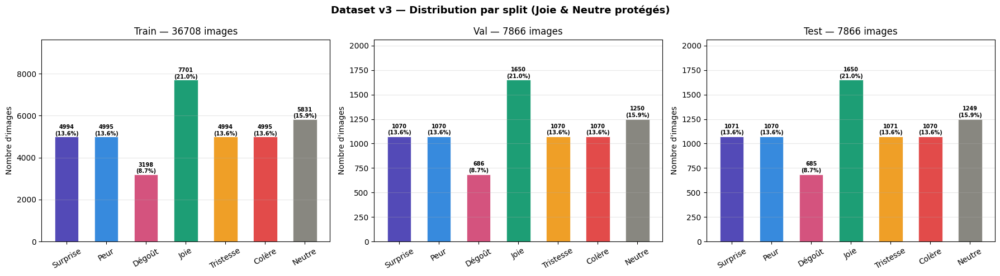

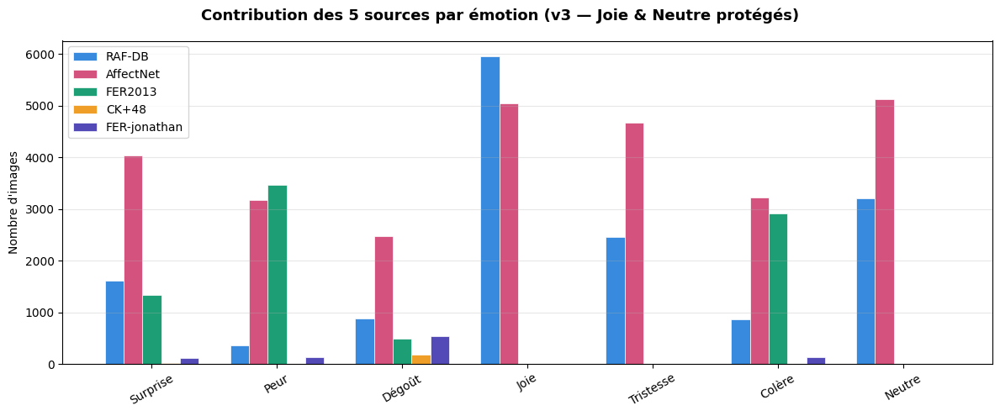


  FICHIERS SAUVEGARDÉS
  emotion_train_combined.csv :  36708 images
  emotion_val_combined.csv   :   7866 images
  emotion_test_combined.csv  :   7866 images

Dataset v3 prêt pour l'entraînement ✅
→ Relancer les DataLoaders et recalculer les class_weights


In [10]:
# ==============================
# COMBINAISON DATASETS v3 — CORRIGÉ
# Équilibrage intelligent : ajouter SEULEMENT ce qui manque
# SAUF Joie (3) et Neutre (6) → INTACTES
# CK+48 + FER-jonathanoheix → compléter les 5 autres classes vers cible
# ==============================

emotion_labels_map = {
    0: "Surprise", 1: "Peur",      2: "Dégoût",
    3: "Joie",     4: "Tristesse", 5: "Colère", 6: "Neutre"
}

# ==============================
# ÉTAPE 1 — CHARGER LE DATASET EXISTANT (RAF + AffectNet + FER2013)
# ==============================
print("Chargement des CSVs existants ...")
df_train_old = pd.read_csv("/kaggle/working/emotion_train_combined.csv")
df_val_old   = pd.read_csv("/kaggle/working/emotion_val_combined.csv")
df_test_old  = pd.read_csv("/kaggle/working/emotion_test_combined.csv")

# Reconstituer le dataset complet
df_existing = pd.concat([df_train_old, df_val_old, df_test_old], ignore_index=True)
df_existing = df_existing.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Dataset existant reconstitué : {len(df_existing)} images")
print(f"  Sources : {df_existing['source'].value_counts().to_dict()}")

print(f"\nDistribution actuelle :")
for cls in range(7):
    n = (df_existing["emotion_class"] == cls).sum()
    print(f"  {emotion_labels_map[cls]:<12} : {n:>6}")

# ==============================
# ÉTAPE 2 — DÉFINIR LA CIBLE
# Cible = max des 5 classes à équilibrer (exclure Joie et Neutre)
# Joie = 11001, Neutre = 8330 → on les ignore
# ==============================
CLASSES_TO_BOOST = [0, 1, 2, 4, 5]  # Surprise, Peur, Dégoût, Tristesse, Colère
CLASSES_PROTECTED = [3, 6]         # Joie, Neutre → INTACTES

# Cible = max parmi les classes à booster
counts_boost = [(df_existing["emotion_class"] == cls).sum() for cls in CLASSES_TO_BOOST]
CIBLE = max(counts_boost)
print(f"\n{'='*55}")
print(f"  CIBLE D'ÉQUILIBRAGE : {CIBLE} images par classe")
print(f"  (max parmi les 5 classes à équilibrer)")
print(f"  ⚠️  Joie et Neutre restent INTACTES")
print(f"{'='*55}")

# ==============================
# ÉTAPE 3 — PARSER CK+48 (toutes les classes utiles)
# ==============================
CKP_PATH = "/kaggle/input/datasets/shawon10/ckplus/CK+48"

ckp_map = {
    "anger"    : 5,
    "contempt" : None,   # Pas dans nos 7 classes → ignoré
    "disgust"  : 2,
    "fear"     : 1,
    "happy"    : 3,
    "sadness"  : 4,
    "surprise" : 0,
}

records_ckp = []
print(f"\nParsing CK+48 (toutes les classes utiles) ...")

for folder in sorted(os.listdir(CKP_PATH)):
    folder_path = os.path.join(CKP_PATH, folder)
    if not os.path.isdir(folder_path):
        continue
    cls = ckp_map.get(folder.lower())
    if cls is None:
        continue  # contempt → ignoré

    for fname in os.listdir(folder_path):
        if not fname.lower().endswith((".jpg", ".png", ".jpeg")):
            continue
        records_ckp.append({
            "filepath"      : os.path.join(folder_path, fname),
            "emotion_class" : cls,
            "emotion_label" : emotion_labels_map[cls],
            "source"        : "ckplus",
        })

df_ckp = pd.DataFrame(records_ckp)
print(f"  CK+48 total : {len(df_ckp)} images")
print(df_ckp["emotion_label"].value_counts().sort_index())

# ==============================
# ÉTAPE 4 — PARSER FER-jonathanoheix (train + validation)
# ==============================
FER2_PATH = "/kaggle/input/datasets/jonathanoheix/face-expression-recognition-dataset/images/images"

fer2_map = {
    "angry"   : 5,
    "disgust" : 2,
    "fear"    : 1,
    "happy"   : 3,
    "neutral" : 6,
    "sad"     : 4,
    "surprise": 0,
}

records_fer2 = []
print(f"\nParsing FER-jonathanoheix (train + validation) ...")

for split in ["train", "validation"]:
    split_path = os.path.join(FER2_PATH, split)
    if not os.path.exists(split_path):
        print(f"  Split '{split}' non trouvé — ignoré")
        continue

    n_split = 0
    for folder in os.listdir(split_path):
        folder_path = os.path.join(split_path, folder)
        if not os.path.isdir(folder_path):
            continue
        cls = fer2_map.get(folder.lower())
        if cls is None:
            continue

        for fname in os.listdir(folder_path):
            if not fname.lower().endswith((".jpg", ".png", ".jpeg")):
                continue
            records_fer2.append({
                "filepath"      : os.path.join(folder_path, fname),
                "emotion_class" : cls,
                "emotion_label" : emotion_labels_map[cls],
                "source"        : "fer_jonathan",
            })
            n_split += 1

    print(f"  [{split}] : {n_split} images")

df_fer2 = pd.DataFrame(records_fer2)
print(f"\n  FER-jonathanoheix total : {len(df_fer2)} images")
print(df_fer2["emotion_label"].value_counts().sort_index())

# ==============================
# ÉTAPE 5 — COMBINER CK+48 et FER-jonathan en un pool boost
# ==============================
df_boost_pool = pd.concat([df_ckp, df_fer2], ignore_index=True)
print(f"\nPool boost total (CK+48 + FER-jonathan) : {len(df_boost_pool)} images")

# ==============================
# ÉTAPE 6 — SÉLECTION INTELLIGENTE : ajouter SEULEMENT ce qui manque
# Joie (3) et Neutre (6) → JAMAIS touchées
# ==============================
records_add = []

print(f"\n{'='*65}")
print(f"  SÉLECTION INTELLIGENTE (cible = {CIBLE} images/classe)")
print(f"  🛡️  Joie et Neutre : INTACTES (pas de boost)")
print(f"{'='*65}")
print(f"  {'Émotion':<12} {'Actuel':>8} {'Manque':>8} {'Dispo CK':>8} {'Dispo FER':>9} {'Total disp':>10} {'Ajouté':>8}")
print(f"  {'─'*60}")

for cls in range(7):
    label = emotion_labels_map[cls]
    actuel = (df_existing["emotion_class"] == cls).sum()

    # Joie et Neutre → protégées, on ne touche pas
    if cls in CLASSES_PROTECTED:
        print(f"  {label:<12} {actuel:>8} {'—':>8} {'—':>8} {'—':>9} {'—':>10} {'0':>8}  🛡️ PROTÉGÉ")
        continue

    manque = max(0, CIBLE - actuel)

    # Images disponibles pour cette classe
    ckp_dispo = df_ckp[df_ckp["emotion_class"] == cls]
    fer2_dispo = df_fer2[df_fer2["emotion_class"] == cls]
    total_dispo = len(ckp_dispo) + len(fer2_dispo)

    # Combien on peut réellement ajouter
    n_prendre = min(manque, total_dispo)

    if n_prendre > 0:
        # Prendre aléatoirement depuis le pool boost (CK+48 + FER-jonathan mélangés)
        pool_cls = df_boost_pool[df_boost_pool["emotion_class"] == cls]
        selected = pool_cls.sample(n=n_prendre, random_state=42)
        records_add.append(selected)

    status = "✅ OK" if manque == 0 else ("⚠️ partiel" if n_prendre < manque else "✅ complété")
    print(f"  {label:<12} {actuel:>8} {manque:>8} {len(ckp_dispo):>8} {len(fer2_dispo):>9} {total_dispo:>10} {n_prendre:>8}  {status}")

if records_add:
    df_boost_selected = pd.concat(records_add, ignore_index=True)
else:
    df_boost_selected = pd.DataFrame(columns=df_existing.columns)

print(f"\n  Images sélectionnées pour ajout : {len(df_boost_selected)}")

# ==============================
# ÉTAPE 7 — COMBINER ET MÉLANGER
# ==============================
df_combined_v3 = pd.concat([df_existing, df_boost_selected], ignore_index=True)
df_combined_v3 = df_combined_v3.sample(frac=1, random_state=42).reset_index(drop=True)

total = len(df_combined_v3)
print(f"\n{'='*55}")
print(f"  DATASET V3 FINAL")
print(f"{'='*55}")
print(f"  Total : {total} images")

print(f"\n  Distribution finale :")
for cls in range(7):
    n_old = (df_existing["emotion_class"] == cls).sum()
    n_new = (df_combined_v3["emotion_class"] == cls).sum()
    diff = n_new - n_old
    flag = f"  (+{diff})" if diff > 0 else ""
    bar = "█" * int(n_new / 300)
    print(f"  {emotion_labels_map[cls]:<12} : {n_new:>6} imgs{flag:<10}  {bar}")

class_counts = df_combined_v3["emotion_class"].value_counts().sort_index()
max_c = class_counts.max()
min_c = class_counts.min()
print(f"\n  Déséquilibre : x{max_c/min_c:.1f}")

# Sources
print(f"\n  Sources dans le dataset v3 :")
for src in df_combined_v3["source"].value_counts().index:
    n = (df_combined_v3["source"] == src).sum()
    pct = n / total * 100
    print(f"    {src:<15} : {n:>6} images ({pct:.1f}%)")

# ==============================
# ÉTAPE 8 — SPLIT 70 / 15 / 15
# ==============================
df_train_emotion, df_temp = train_test_split(
    df_combined_v3,
    test_size    = 0.30,
    random_state = 42,
    stratify     = df_combined_v3["emotion_class"]
)
df_val_emotion, df_test_emotion = train_test_split(
    df_temp,
    test_size    = 0.50,
    random_state = 42,
    stratify     = df_temp["emotion_class"]
)

print(f"\n{'='*50}")
print(f"  SPLITS FINAUX v3")
print(f"{'='*50}")
print(f"  Train : {len(df_train_emotion):>6} images ({len(df_train_emotion)/total*100:.1f}%)")
print(f"  Val   : {len(df_val_emotion):>6} images ({len(df_val_emotion)/total*100:.1f}%)")
print(f"  Test  : {len(df_test_emotion):>6} images ({len(df_test_emotion)/total*100:.1f}%)")

print(f"\n{'─'*60}")
print(f"  DISTRIBUTION PAR SPLIT")
print(f"{'─'*60}")
print(f"  {'Émotion':<12} {'Train':>7} {'Val':>7} {'Test':>7}  {'Équilibré?':>10}")
print(f"  {'─'*54}")

for cls in range(7):
    label    = emotion_labels_map[cls]
    t_count  = (df_train_emotion["emotion_class"] == cls).sum()
    v_count  = (df_val_emotion["emotion_class"]   == cls).sum()
    te_count = (df_test_emotion["emotion_class"]  == cls).sum()
    t_pct    = t_count  / len(df_train_emotion) * 100
    v_pct    = v_count  / len(df_val_emotion)   * 100
    te_pct   = te_count / len(df_test_emotion)  * 100
    ok       = "✅" if abs(t_pct - v_pct) < 2 and abs(t_pct - te_pct) < 2 else "⚠️"
    print(f"  {label:<12} {t_count:>7} {v_count:>7} {te_count:>7}  {ok:>10}")

# ==============================
# ÉTAPE 9 — VISUALISATION
# ==============================
labels_ordered = [emotion_labels_map[i] for i in range(7)]
colors_ordered = ["#534AB7", "#378ADD", "#D4537E", "#1D9E75", "#EF9F27", "#E24B4A", "#888780"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Dataset v3 — Distribution par split (Joie & Neutre protégés)", fontsize=13, fontweight="bold")

for ax, (split_df, split_name) in zip(axes, [
    (df_train_emotion, "Train"),
    (df_val_emotion,   "Val"),
    (df_test_emotion,  "Test"),
]):
    counts = [(split_df["emotion_class"] == cls).sum() for cls in range(7)]
    bars   = ax.bar(labels_ordered, counts, color=colors_ordered,
                    edgecolor="white", linewidth=0.5, width=0.6)
    for bar, count in zip(bars, counts):
        pct = count / len(split_df) * 100
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 10,
                f"{count}\n({pct:.1f}%)",
                ha="center", va="bottom", fontsize=7, fontweight="bold")
    ax.set_title(f"{split_name} — {len(split_df)} images")
    ax.set_ylabel("Nombre d'images")
    ax.tick_params(axis="x", rotation=30)
    ax.set_ylim(0, max(counts) * 1.25)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/v3_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

# Contribution des sources
fig, ax = plt.subplots(figsize=(12, 5))
fig.suptitle("Contribution des 5 sources par émotion (v3 — Joie & Neutre protégés)", fontsize=13, fontweight="bold")

x     = np.arange(7)
width = 0.15

sources = [
    ("rafdb",        "RAF-DB",       "#378ADD"),
    ("affectnet",    "AffectNet",    "#D4537E"),
    ("fer2013",      "FER2013",      "#1D9E75"),
    ("ckplus",       "CK+48",        "#EF9F27"),
    ("fer_jonathan", "FER-jonathan", "#534AB7"),
]

for i, (src, label, color) in enumerate(sources):
    vals = [(df_combined_v3[df_combined_v3["source"] == src]["emotion_class"] == cls).sum()
            for cls in range(7)]
    ax.bar(x + (i - 2) * width, vals, width,
           label=label, color=color, edgecolor="white", linewidth=0.5)

ax.set_xticks(x)
ax.set_xticklabels(labels_ordered, rotation=30)
ax.set_ylabel("Nombre d'images")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/v3_sources_contribution.png", dpi=120, bbox_inches="tight")
plt.show()

# ==============================
# ÉTAPE 10 — SAUVEGARDER
# ==============================
df_train_emotion.to_csv("/kaggle/working/emotion_train_combined.csv", index=False)
df_val_emotion.to_csv("/kaggle/working/emotion_val_combined.csv",     index=False)
df_test_emotion.to_csv("/kaggle/working/emotion_test_combined.csv",   index=False)

print(f"\n{'='*50}")
print(f"  FICHIERS SAUVEGARDÉS")
print(f"{'='*50}")
print(f"  emotion_train_combined.csv : {len(df_train_emotion):>6} images")
print(f"  emotion_val_combined.csv   : {len(df_val_emotion):>6} images")
print(f"  emotion_test_combined.csv  : {len(df_test_emotion):>6} images")
print(f"\nDataset v3 prêt pour l'entraînement ✅")
print(f"→ Relancer les DataLoaders et recalculer les class_weights")

# 4. Dataset PyTorch + DataLoader

## 4.1. Configuration

In [11]:
# ==============================
# CONFIGURATION
# ==============================
IMG_SIZE   = 112
BATCH_SIZE = 32
AGE_MAX    = 100.0

def normalize_age(age):
    """Normalise l'âge [0, AGE_MAX] → [0, 1]"""
    return float(age) / AGE_MAX

def denormalize_age(age_norm):
    """Remet à l'échelle [0, 1] → [0, AGE_MAX] pour métriques et affichage"""
    return age_norm * AGE_MAX

print(f"Image size : {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch size : {BATCH_SIZE}")
print(f"AGE_MAX    : {AGE_MAX}  →  normalize_age / denormalize_age définis")

# ==============================
# TRANSFORMS (preprocessing + augmentation)
# ==============================
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.RandomGrayscale(p=0.1),
    transforms.ColorJitter(
        brightness=0.4,
        contrast=0.4,
        saturation=0.3,
        hue=0.05
    ),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
    transforms.RandomErasing(
        p=0.3,
        scale=(0.02, 0.15),
        ratio=(0.3, 3.3),
        value=0
    ),
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

print("Transforms définis :")
print("  train_transform    : resize + flip + rotation(20°) + grayscale + colorjitter + blur + erasing + normalize")
print("  val_test_transform : resize + normalize uniquement")

Image size : 112x112
Batch size : 32
AGE_MAX    : 100.0  →  normalize_age / denormalize_age définis
Transforms définis :
  train_transform    : resize + flip + rotation(20°) + grayscale + colorjitter + blur + erasing + normalize
  val_test_transform : resize + normalize uniquement


## 4.2. UTKFace Dataset

In [12]:
print(f"df en mémoire : {len(df)} images")

# ==============================
# SPLIT 70% / 15% / 15%
# Sans stratify car âge en régression
# (pas de classes discrètes à équilibrer)
# ==============================
df_train_utk, df_temp = train_test_split(
    df,
    test_size    = 0.30,
    random_state = 42,
    stratify     = df["gender"]   
)
df_val_utk, df_test_utk = train_test_split(
    df_temp,
    test_size    = 0.50,
    random_state = 42,
    stratify     = df_temp["gender"]
)

# Sauvegarder
df_train_utk.to_csv("/kaggle/working/utk_train.csv", index=False)
df_val_utk.to_csv("/kaggle/working/utk_val.csv",     index=False)
df_test_utk.to_csv("/kaggle/working/utk_test.csv",   index=False)

print(f"Train : {len(df_train_utk)} images | âge moyen : {df_train_utk['age'].mean():.1f} ans")
print(f"Val   : {len(df_val_utk)} images | âge moyen : {df_val_utk['age'].mean():.1f} ans")
print(f"Test  : {len(df_test_utk)} images | âge moyen : {df_test_utk['age'].mean():.1f} ans")

print(f"\nDistribution âge par split :")
for split_name, split_df in [("Train", df_train_utk), ("Val", df_val_utk), ("Test", df_test_utk)]:
    print(f"  {split_name} → min={split_df['age'].min()} · max={split_df['age'].max()} · "
          f"mean={split_df['age'].mean():.1f} · std={split_df['age'].std():.1f}")

print("\nFichiers créés :")
for f in os.listdir("/kaggle/working"):
    if f.startswith("utk"):
        print(f"  {f}")

df en mémoire : 23708 images
Train : 16595 images | âge moyen : 33.4 ans
Val   : 3556 images | âge moyen : 33.2 ans
Test  : 3557 images | âge moyen : 32.8 ans

Distribution âge par split :
  Train → min=1 · max=116 · mean=33.4 · std=19.9
  Val → min=1 · max=115 · mean=33.2 · std=20.0
  Test → min=1 · max=116 · mean=32.8 · std=19.8

Fichiers créés :
  utk_exemples.png
  utk_vs_imdb_contribution.png
  utk_train.csv
  utk_distribution.png
  utk_val.csv
  utk_test.csv


In [13]:
class UTKFaceDataset(Dataset):
    """
    Dataset PyTorch pour UTKFace.
    Retourne : image, gender (0/1), age (float — âge exact 0-116)
    """
    def __init__(self, csv_path, transform=None):
        self.df        = pd.read_csv(csv_path)
        self.transform = transform
        required = ["filepath", "gender", "age"]   # ← "age" pas "age_class"
        for col in required:
            if col not in self.df.columns:
                raise ValueError(f"Colonne manquante dans le CSV : {col}")
        print(f"UTKFaceDataset chargé : {len(self.df)} images — {csv_path}")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row["filepath"]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        gender = torch.tensor(row["gender"], dtype=torch.long)
        age_norm = torch.tensor(normalize_age(row["age"]), dtype=torch.float32)  # ← directement depuis row, pas depuis tensor
        return image, gender, age_norm

# ── Test rapide ──────────────────────────────────────────
dataset_test_utk = UTKFaceDataset(
    csv_path  = "/kaggle/working/utk_train.csv",
    transform = train_transform
)
image, gender, age = dataset_test_utk[0]
print(f"\nTest UTKFaceDataset :")
print(f"  Taille dataset : {len(dataset_test_utk)}")
print(f"  Shape image    : {image.shape}")
print(f"  Gender label   : {gender.item()}")
print(f"  Age normalisé  : {age.item():.4f}  (≈ {age.item() * AGE_MAX:.0f} ans réels)")  # ← corrigé

UTKFaceDataset chargé : 16595 images — /kaggle/working/utk_train.csv

Test UTKFaceDataset :
  Taille dataset : 16595
  Shape image    : torch.Size([3, 112, 112])
  Gender label   : 0
  Age normalisé  : 0.5300  (≈ 53 ans réels)


## 4.3. Emotion Dataset

In [14]:
class EmotionDataset(Dataset):
    """
    Dataset PyTorch pour émotions (RAF-DB + AffectNet combinés).
    Retourne : image, emotion_class (0→6)
    """
    def __init__(self, csv_path, transform=None):
        self.df        = pd.read_csv(csv_path)
        self.transform = transform
        required = ["filepath", "emotion_class"]
        for col in required:
            if col not in self.df.columns:
                raise ValueError(f"Colonne manquante dans le CSV : {col}")
        print(f"EmotionDataset chargé : {len(self.df)} images — {csv_path}")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row["filepath"]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        emotion = torch.tensor(row["emotion_class"], dtype=torch.long)
        return image, emotion

# ── Test rapide ──────────────────────────────────────────
dataset_test_emotion = EmotionDataset(
    csv_path  = "/kaggle/working/emotion_train_combined.csv",
    transform = train_transform
)
image, emotion = dataset_test_emotion[0]
print(f"\nTest EmotionDataset :")
print(f"  Taille dataset     : {len(dataset_test_emotion)}")
print(f"  Shape image        : {image.shape}")
print(f"  Emotion label      : {emotion.item()}")

EmotionDataset chargé : 36708 images — /kaggle/working/emotion_train_combined.csv

Test EmotionDataset :
  Taille dataset     : 36708
  Shape image        : torch.Size([3, 112, 112])
  Emotion label      : 1


## 4.4. Création de tous les DataLoaders

In [15]:
device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32

# ==============================
# TOUS LES DATASETS
# ==============================
utk_train_dataset     = UTKFaceDataset("/kaggle/working/utk_train.csv",
                                        transform=train_transform)
utk_val_dataset       = UTKFaceDataset("/kaggle/working/utk_val.csv",
                                        transform=val_test_transform)
utk_test_dataset      = UTKFaceDataset("/kaggle/working/utk_test.csv",
                                        transform=val_test_transform)

emotion_train_dataset = EmotionDataset("/kaggle/working/emotion_train_combined.csv",
                                        transform=train_transform)
emotion_val_dataset   = EmotionDataset("/kaggle/working/emotion_val_combined.csv",
                                        transform=val_test_transform)
emotion_test_dataset  = EmotionDataset("/kaggle/working/emotion_test_combined.csv",
                                        transform=val_test_transform)

# ==============================
# TOUS LES DATALOADERS
# ==============================
utk_train_loader     = DataLoader(utk_train_dataset,     batch_size=BATCH_SIZE,
                                   shuffle=True,  num_workers=2, pin_memory=True)
utk_val_loader       = DataLoader(utk_val_dataset,       batch_size=BATCH_SIZE,
                                   shuffle=False, num_workers=2, pin_memory=True)
utk_test_loader      = DataLoader(utk_test_dataset,      batch_size=BATCH_SIZE,
                                   shuffle=False, num_workers=2, pin_memory=True)

emotion_train_loader = DataLoader(emotion_train_dataset, batch_size=BATCH_SIZE,
                                   shuffle=True,  num_workers=2, pin_memory=True)
emotion_val_loader   = DataLoader(emotion_val_dataset,   batch_size=BATCH_SIZE,
                                   shuffle=False, num_workers=2, pin_memory=True)
emotion_test_loader  = DataLoader(emotion_test_dataset,  batch_size=BATCH_SIZE,
                                   shuffle=False, num_workers=2, pin_memory=True)

# ==============================
# RÉSUMÉ
# ==============================
print("=" * 55)
print("  RÉSUMÉ DATALOADERS")
print("=" * 55)

print(f"\nUTKFace (âge en régression) :")
print(f"  Train  : {len(utk_train_dataset):>6} imgs → {len(utk_train_loader):>4} batches")
print(f"  Val    : {len(utk_val_dataset):>6} imgs → {len(utk_val_loader):>4} batches")
print(f"  Test   : {len(utk_test_dataset):>6} imgs → {len(utk_test_loader):>4} batches")

print(f"\nÉmotion combiné (RAF-DB + AffectNet + FER2013) :")
print(f"  Train  : {len(emotion_train_dataset):>6} imgs → {len(emotion_train_loader):>4} batches")
print(f"  Val    : {len(emotion_val_dataset):>6} imgs → {len(emotion_val_loader):>4} batches")
print(f"  Test   : {len(emotion_test_dataset):>6} imgs → {len(emotion_test_loader):>4} batches")

# ==============================
# VÉRIFICATION UN BATCH
# ==============================
images_utk,     genders, ages = next(iter(utk_train_loader))
images_emotion, emotions      = next(iter(emotion_train_loader))

print(f"\nVérification batch :")
print(f"  UTKFace — images : {images_utk.shape} "
      f"| genders : {genders[:6].tolist()} "
      f"| ages (réels) : {[round(a) for a in ages[:6].tolist()]}")  # ← âges exacts
print(f"  Émotion — images : {images_emotion.shape} "
      f"| emotions : {emotions[:6].tolist()}")

# Transfert GPU
images_utk.to(device)
images_emotion.to(device)
print(f"\nTransfert GPU OK")
print(f"Device : {device}")
print(f"Mémoire GPU utilisée : {torch.cuda.memory_allocated()/1e6:.1f} Mo")
print("\nDataLoaders prêts ✅")

UTKFaceDataset chargé : 16595 images — /kaggle/working/utk_train.csv
UTKFaceDataset chargé : 3556 images — /kaggle/working/utk_val.csv
UTKFaceDataset chargé : 3557 images — /kaggle/working/utk_test.csv
EmotionDataset chargé : 36708 images — /kaggle/working/emotion_train_combined.csv
EmotionDataset chargé : 7866 images — /kaggle/working/emotion_val_combined.csv
EmotionDataset chargé : 7866 images — /kaggle/working/emotion_test_combined.csv
  RÉSUMÉ DATALOADERS

UTKFace (âge en régression) :
  Train  :  16595 imgs →  519 batches
  Val    :   3556 imgs →  112 batches
  Test   :   3557 imgs →  112 batches

Émotion combiné (RAF-DB + AffectNet + FER2013) :
  Train  :  36708 imgs → 1148 batches
  Val    :   7866 imgs →  246 batches
  Test   :   7866 imgs →  246 batches

Vérification batch :
  UTKFace — images : torch.Size([32, 3, 112, 112]) | genders : [1, 0, 0, 1, 1, 0] | ages (réels) : [0, 0, 0, 0, 1, 1]
  Émotion — images : torch.Size([32, 3, 112, 112]) | emotions : [3, 1, 0, 3, 5, 3]

Tra

# 5. Chargement du backbone MOBILENETV3 pré-entraîné

In [16]:
# ==============================
# CHARGER MOBILENETV3-LARGE PRÉ-ENTRAÎNÉ
# ==============================
mobilenet = models.mobilenet_v3_large(
    weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V2
)

print("Structure MobileNetV3-Large :")
for name, module in mobilenet.named_children():
    print(f"  {name:<12} : {module.__class__.__name__}")

print(f"\nDernière couche (classifier) : {mobilenet.classifier}")
print(f"Sortie backbone (après avgpool) : 960 features")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 160MB/s]

Structure MobileNetV3-Large :
  features     : Sequential
  avgpool      : AdaptiveAvgPool2d
  classifier   : Sequential

Dernière couche (classifier) : Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1280, out_features=1000, bias=True)
)
Sortie backbone (après avgpool) : 960 features


# 6. Architecture MTL complète

In [17]:
class MTLFaceModel(nn.Module):
    """
    Modèle Multi-Task Learning — Backbone MobileNetV3-Large
    - Backbone : MobileNetV3-Large pré-entraîné (features = 960 → pool → 960)
    - Tête 1   : Genre     (2 classes)
    - Tête 2   : Âge       (régression normalisée [0,1])
    - Tête 3   : Émotion   (7 classes)
    """

    def __init__(self, freeze_backbone=True):
        super(MTLFaceModel, self).__init__()

        # ── BACKBONE ─────────────────────────────────────────
        mobilenet = models.mobilenet_v3_large(
            weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V2
        )
        # MobileNetV3 : features (conv layers) + avgpool → sortie 960-dim
        self.backbone = nn.Sequential(
            mobilenet.features,
            mobilenet.avgpool,       # → [batch, 960, 1, 1]
        )
        FEAT_DIM = 960

        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False

        # ── TÊTE GENRE ───────────────────────────────────────
        self.head_gender = nn.Sequential(
            nn.Dropout(p=0.4),
            nn.Linear(FEAT_DIM, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Linear(256, 2)
        )

        # ── TÊTE ÂGE — RÉGRESSION ────────────────────────────
        self.head_age = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.Linear(FEAT_DIM, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

        # ── TÊTE ÉMOTION ─────────────────────────────────────
        self.head_emotion = nn.Sequential(
            nn.Dropout(p=0.5),
            nn.Linear(FEAT_DIM, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(512, 7)
        )

    def forward(self, x):
        features = self.backbone(x)        # [batch, 960, 1, 1]
        features = features.flatten(1)     # [batch, 960]

        out_gender  = self.head_gender(features)
        out_age     = self.head_age(features)
        out_emotion = self.head_emotion(features)

        return out_gender, out_age, out_emotion

    def unfreeze_backbone(self, last_n_layers=2):
        children = list(self.backbone[0].children())  # features = Sequential
        for layer in children[-last_n_layers:]:
            for param in layer.parameters():
                param.requires_grad = True
        n_trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        print(f"Backbone MobileNetV3 partiellement dégelé ({last_n_layers} derniers blocs)")
        print(f"Paramètres entraînables : {n_trainable:,}")


# ==============================
# INSTANCIER + VÉRIFIER
# ==============================
model = MTLFaceModel(freeze_backbone=True).to(device)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("=" * 50)
print("  ARCHITECTURE — MobileNetV3-Large MTL")
print("=" * 50)
print(f"  Backbone feature dim   : 960")
print(f"  Paramètres totaux      : {total_params:>10,}")
print(f"  Paramètres gelés       : {total_params - trainable_params:>10,}")
print(f"  Paramètres entraînables: {trainable_params:>10,}  ({trainable_params/total_params*100:.1f}%)")

# Test forward pass
model.eval()
dummy = torch.randn(4, 3, 112, 112).to(device)
with torch.no_grad():
    og, oa, oe = model(dummy)
print(f"\n  Forward pass OK :")
print(f"  Genre   : {og.shape}   Âge : {oa.shape}   Émotion : {oe.shape}")

# Sauvegarder dans un dossier dédié
import os
os.makedirs("/kaggle/working/mobilenet", exist_ok=True)
print(f"\n  Outputs → /kaggle/working/mobilenet/")

  ARCHITECTURE — MobileNetV3-Large MTL
  Backbone feature dim   : 960
  Paramètres totaux      :  4,274,746
  Paramètres gelés       :  2,971,952
  Paramètres entraînables:  1,302,794  (30.5%)

  Forward pass OK :
  Genre   : torch.Size([4, 2])   Âge : torch.Size([4, 1])   Émotion : torch.Size([4, 7])

  Outputs → /kaggle/working/mobilenet/


# 7. Test du forward pass

In [18]:
# ==============================
# TEST FORWARD PASS
# ==============================
model.eval()

# Batch factice
dummy_batch = torch.randn(8, 3, 112, 112).to(device)
with torch.no_grad():
    out_gender, out_age, out_emotion = model(dummy_batch)

print("Test forward pass :")
print(f"  Input shape    : {dummy_batch.shape}")
print(f"  Genre  output  : {out_gender.shape}")    # [8, 2]
print(f"  Âge    output  : {out_age.shape}")       # [8, 1] ← régression
print(f"  Émotion output : {out_emotion.shape}")   # [8, 7]

# Vérifier sur un vrai batch UTKFace
model.eval()
images_utk, genders, ages = next(iter(utk_train_loader))
images_utk = images_utk.to(device)

with torch.no_grad():
    out_gender, out_age, out_emotion = model(images_utk)

pred_gender  = out_gender.argmax(dim=1)
pred_age     = out_age.squeeze()          # ← squeeze [batch,1] → [batch]

print(f"\nTest sur batch réel UTKFace :")
print(f"  Genre — réel : {genders[:6].tolist()}")
print(f"  Genre — préd : {pred_gender[:6].tolist()}")
print(f"  Âge   — réel : {[round(a) for a in ages[:6].tolist()]} ans")
print(f"  Âge   — préd : {[round(a) for a in pred_age[:6].tolist()]} ans")
print(f"\nForward pass OK — modèle prêt pour l'entraînement")

Test forward pass :
  Input shape    : torch.Size([8, 3, 112, 112])
  Genre  output  : torch.Size([8, 2])
  Âge    output  : torch.Size([8, 1])
  Émotion output : torch.Size([8, 7])

Test sur batch réel UTKFace :
  Genre — réel : [1, 1, 0, 0, 0, 0]
  Genre — préd : [1, 1, 1, 0, 0, 1]
  Âge   — réel : [0, 0, 1, 0, 0, 0] ans
  Âge   — préd : [0, 0, 0, 0, 0, 0] ans

Forward pass OK — modèle prêt pour l'entraînement


# 8. Définition des losses, optimizer et scheduler

In [19]:
# ==============================
# NORMALISATION DE L'ÂGE
# ==============================
# L'âge brut (0-116) crée un déséquilibre de gradient face aux losses genre/émotion
# qui travaillent sur des logits ~0-1. On normalise entre 0 et 1.
AGE_MAX = 100.0   # on clampe à 100 (les >100 sont rares et bruités dans IMDB-Wiki)

def normalize_age(age):
    """Normalise l'âge [0, AGE_MAX] → [0, 1]"""
    return float(age) / AGE_MAX

def denormalize_age(age_norm):
    """Remet à l'échelle [0, 1] → [0, AGE_MAX] pour les métriques et l'affichage"""
    return age_norm * AGE_MAX

print(f"Normalisation âge : valeur / {AGE_MAX}  →  plage [0.0, 1.0]")
print(f"  ⚠️  Appliquer normalize_age() dans le Dataset.__getitem__() pour l'âge")
print(f"  ⚠️  Appliquer denormalize_age() sur les prédictions avant MAE et affichage")

# ==============================
# CONFIGURATION EPOCHS
# ==============================
N_EPOCHS_PHASE1 = 30
N_EPOCHS_PHASE2 = 75
print(f"\nEpochs Phase 1 : {N_EPOCHS_PHASE1}")
print(f"Epochs Phase 2 : {N_EPOCHS_PHASE2}")

# ==============================
# CLASS WEIGHTS
# ==============================
weights_gender = compute_class_weight(
    class_weight = "balanced",
    classes      = np.array([0, 1]),
    y            = df["gender"].values
)
weights_emotion = compute_class_weight(
    class_weight = "balanced",
    classes      = np.array([0, 1, 2, 3, 4, 5, 6]),
    y            = df_train_emotion["emotion_class"].values
)
w_gender  = torch.FloatTensor(weights_gender).to(device)
w_emotion = torch.FloatTensor(weights_emotion).to(device)

print("\nClass weights Genre   :", [f"{w:.3f}" for w in weights_gender])
print("Class weights Émotion :", [f"{w:.3f}" for w in weights_emotion])

# ==============================
# LOSS FUNCTIONS
# ==============================
criterion_gender  = nn.CrossEntropyLoss(weight=w_gender)
criterion_age     = nn.HuberLoss(delta=0.05)  
criterion_emotion = nn.CrossEntropyLoss(weight=w_emotion, label_smoothing=0.1) 

print("\nLoss functions :")
print("  Genre   : CrossEntropyLoss + class_weight")
print(f"  Âge     : HuberLoss (régression, delta=0.05 → équivaut à {0.05 * AGE_MAX:.0f} ans réels)")
print("  Émotion : CrossEntropyLoss + class_weight + label_smoothing=0.1")

# ==============================
# LAMBDAS — PONDÉRATION DES LOSSES
# ==============================
# Avec l'âge normalisé, la loss_age est maintenant ~100x plus petite qu'avant.
# On augmente lambda_age en conséquence pour rééquilibrer.
lambda_gender  = 1.0
lambda_age     = 10.0   # était 0.1 → x100 car âge normalisé (loss ~100x plus petite)
lambda_emotion = 1.5

print(f"\nLambdas : genre={lambda_gender} · âge={lambda_age} · émotion={lambda_emotion}")
print("  ℹ️  lambda_age=10.0 compense la normalisation (loss âge ÷100 après normalisation)")

# ==============================
# OPTIMIZER — PHASE 1
# ==============================
optimizer = torch.optim.Adam([
    {"params": model.head_gender.parameters(),  "lr": 1e-3},
    {"params": model.head_age.parameters(),     "lr": 1e-3},
    {"params": model.head_emotion.parameters(), "lr": 1e-3},
], weight_decay=1e-4)

print(f"\nOptimizer Phase 1 : Adam")
print(f"  Têtes lr     : 1e-3")
print(f"  Weight decay : 1e-4")

# ==============================
# SCHEDULER — PHASE 1
# ==============================
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode     = "min",
    patience = 6,
    factor   = 0.5
)

print(f"\nScheduler : ReduceLROnPlateau")
print(f"  Mode      : min (val_loss)")
print(f"  Patience  : 6 epochs")
print(f"  Factor    : 0.5 (lr ÷ 2)")

Normalisation âge : valeur / 100.0  →  plage [0.0, 1.0]
  ⚠️  Appliquer normalize_age() dans le Dataset.__getitem__() pour l'âge
  ⚠️  Appliquer denormalize_age() sur les prédictions avant MAE et affichage

Epochs Phase 1 : 30
Epochs Phase 2 : 75

Class weights Genre   : ['0.957', '1.047']
Class weights Émotion : ['1.050', '1.050', '1.640', '0.681', '1.050', '1.050', '0.899']

Loss functions :
  Genre   : CrossEntropyLoss + class_weight
  Âge     : HuberLoss (régression, delta=0.05 → équivaut à 5 ans réels)
  Émotion : CrossEntropyLoss + class_weight + label_smoothing=0.1

Lambdas : genre=1.0 · âge=10.0 · émotion=1.5
  ℹ️  lambda_age=10.0 compense la normalisation (loss âge ÷100 après normalisation)

Optimizer Phase 1 : Adam
  Têtes lr     : 1e-3
  Weight decay : 1e-4

Scheduler : ReduceLROnPlateau
  Mode      : min (val_loss)
  Patience  : 6 epochs
  Factor    : 0.5 (lr ÷ 2)


# 9. Fonctions utilitaires

In [20]:
def compute_accuracy(outputs, labels):
    """Calcule l'accuracy depuis les logits."""
    preds = outputs.argmax(dim=1)
    return (preds == labels).float().mean().item()

def compute_mae(outputs, labels):
    """
    Calcule le MAE pour la régression d'âge.
    outputs : prédictions normalisées [0,1]
    labels  : labels normalisés [0,1]
    → dénormalisé en ans réels avant le MAE pour un monitoring lisible
    """
    preds      = outputs.squeeze()                  # [batch,1] → [batch]
    preds_real = preds  * AGE_MAX                   # → ans réels
    labels_real = labels.float() * AGE_MAX          # → ans réels
    return torch.abs(preds_real - labels_real).mean().item()


def train_one_epoch(model, utk_loader, emotion_loader, optimizer):
    """Une epoch d'entraînement MTL."""
    model.train()

    total_loss   = 0.0
    loss_g_total = 0.0
    loss_a_total = 0.0
    loss_e_total = 0.0
    acc_g_total  = 0.0
    mae_a_total  = 0.0
    acc_e_total  = 0.0
    n_batches    = 0

    for (imgs_utk, genders, ages), (imgs_emotion, emotions) in zip(utk_loader, emotion_loader):

        imgs_utk     = imgs_utk.to(device)
        genders      = genders.to(device)
        ages         = ages.to(device)          # float32 normalisé [0,1]
        imgs_emotion = imgs_emotion.to(device)
        emotions     = emotions.to(device)

        optimizer.zero_grad()

        # ── Forward pass UTKFace ──────────────────────────
        out_g, out_a, _ = model(imgs_utk)
        loss_g = criterion_gender(out_g, genders)
        loss_a = criterion_age(
            out_a.squeeze(),    # [batch,1] → [batch]
            ages.float()        # labels normalisés [0,1]
        )

        # ── Forward pass Émotion combiné ──────────────────
        _, _, out_e = model(imgs_emotion)
        loss_e = criterion_emotion(out_e, emotions)

        # ── Loss totale ───────────────────────────────────
        loss = lambda_gender  * loss_g + \
               lambda_age     * loss_a + \
               lambda_emotion * loss_e

        # ── Backward ──────────────────────────────────────
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss   += loss.item()
        loss_g_total += loss_g.item()
        loss_a_total += loss_a.item()
        loss_e_total += loss_e.item()
        acc_g_total  += compute_accuracy(out_g, genders)
        mae_a_total  += compute_mae(out_a, ages)   # ← MAE en ans réels
        acc_e_total  += compute_accuracy(out_e, emotions)
        n_batches    += 1

    return {
        "loss"        : total_loss   / n_batches,
        "loss_g"      : loss_g_total / n_batches,
        "loss_a"      : loss_a_total / n_batches,
        "loss_e"      : loss_e_total / n_batches,
        "acc_gender"  : acc_g_total  / n_batches,
        "mae_age"     : mae_a_total  / n_batches,   # en ans réels
        "acc_emotion" : acc_e_total  / n_batches,
    }


def validate(model, utk_loader, emotion_loader):
    """Validation sur val set."""
    model.eval()

    total_loss   = 0.0
    loss_g_total = 0.0
    loss_a_total = 0.0
    loss_e_total = 0.0
    acc_g_total  = 0.0
    mae_a_total  = 0.0
    acc_e_total  = 0.0
    n_batches    = 0
    all_preds_e  = []
    all_labels_e = []

    with torch.no_grad():
        for (imgs_utk, genders, ages), (imgs_emotion, emotions) in zip(utk_loader, emotion_loader):

            imgs_utk     = imgs_utk.to(device)
            genders      = genders.to(device)
            ages         = ages.to(device)
            imgs_emotion = imgs_emotion.to(device)
            emotions     = emotions.to(device)

            out_g, out_a, _ = model(imgs_utk)
            _, _,  out_e    = model(imgs_emotion)

            loss_g = criterion_gender(out_g, genders)
            loss_a = criterion_age(out_a.squeeze(), ages.float())
            loss_e = criterion_emotion(out_e, emotions)
            loss   = lambda_gender  * loss_g + \
                     lambda_age     * loss_a + \
                     lambda_emotion * loss_e

            total_loss   += loss.item()
            loss_g_total += loss_g.item()
            loss_a_total += loss_a.item()
            loss_e_total += loss_e.item()
            acc_g_total  += compute_accuracy(out_g, genders)
            mae_a_total  += compute_mae(out_a, ages)   
            acc_e_total  += compute_accuracy(out_e, emotions)

            all_preds_e.extend(out_e.argmax(dim=1).cpu().tolist())
            all_labels_e.extend(emotions.cpu().tolist())
            n_batches += 1

    f1_emotion = f1_score(all_labels_e, all_preds_e,
                          average="macro", zero_division=0)

    return {
        "loss"        : total_loss   / n_batches,
        "loss_g"      : loss_g_total / n_batches,
        "loss_a"      : loss_a_total / n_batches,
        "loss_e"      : loss_e_total / n_batches,
        "acc_gender"  : acc_g_total  / n_batches,
        "mae_age"     : mae_a_total  / n_batches,   
        "acc_emotion" : acc_e_total  / n_batches,
        "f1_emotion"  : f1_emotion,
    }

print("Fonctions train_one_epoch et validate définies ✅")
print("  ↳ compute_mae retourne maintenant le MAE en ANS RÉELS (dénormalisé)")

Fonctions train_one_epoch et validate définies ✅
  ↳ compute_mae retourne maintenant le MAE en ANS RÉELS (dénormalisé)


# 10. Boucle d'entraînement

In [21]:
# ==============================
# PHASE 1 — BACKBONE GELÉ
# ==============================
best_val_loss = float("inf")
best_epoch    = 0
history       = []

print("=" * 65)
print("  PHASE 1 — BACKBONE GELÉ — ENTRAÎNEMENT DES TÊTES")
print("=" * 65)
print(f"  Epochs     : {N_EPOCHS_PHASE1}")
print(f"  Batch size : {BATCH_SIZE}")
print(f"  Device     : {device}")
print("=" * 65)

for epoch in range(1, N_EPOCHS_PHASE1 + 1):
    t0 = time.time()

    train_metrics = train_one_epoch(
        model, utk_train_loader, emotion_train_loader, optimizer
    )
    val_metrics = validate(
        model, utk_val_loader, emotion_val_loader
    )

    scheduler.step(val_metrics["loss"])

    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        best_epoch    = epoch
        torch.save(model.state_dict(), "/kaggle/working/best_model.pth")
        saved = "  ← SAUVEGARDÉ"
    else:
        saved = ""

    history.append({
        "epoch"      : epoch,
        "train_loss" : train_metrics["loss"],
        "val_loss"   : val_metrics["loss"],
        **{f"train_{k}": v for k, v in train_metrics.items() if k != "loss"},
        **{f"val_{k}":   v for k, v in val_metrics.items()   if k != "loss"},
    })

    elapsed = time.time() - t0
    print(f"\nEpoch {epoch:>2}/{N_EPOCHS_PHASE1}  ({elapsed:.0f}s)")
    print(f"  TRAIN  loss={train_metrics['loss']:.4f} "
          f"| genre={train_metrics['acc_gender']*100:.1f}% "
          f"| mae_age={train_metrics['mae_age']:.1f}ans "   # ← MAE
          f"| émotion={train_metrics['acc_emotion']*100:.1f}%")
    print(f"  VAL    loss={val_metrics['loss']:.4f} "
          f"| genre={val_metrics['acc_gender']*100:.1f}% "
          f"| mae_age={val_metrics['mae_age']:.1f}ans "     # ← MAE
          f"| émotion={val_metrics['acc_emotion']*100:.1f}% "
          f"| F1={val_metrics['f1_emotion']:.3f}"
          f"{saved}")

print(f"\nPhase 1 terminée — meilleur modèle : epoch {best_epoch} "
      f"(val_loss={best_val_loss:.4f})")
print("Sauvegardé : /kaggle/working/best_model.pth")

  PHASE 1 — BACKBONE GELÉ — ENTRAÎNEMENT DES TÊTES
  Epochs     : 30
  Batch size : 32
  Device     : cuda

Epoch  1/30  (158s)
  TRAIN  loss=3.4071 | genre=70.4% | mae_age=12.5ans | émotion=28.7%
  VAL    loss=3.1034 | genre=78.1% | mae_age=10.0ans | émotion=35.3% | F1=0.334  ← SAUVEGARDÉ

Epoch  2/30  (101s)
  TRAIN  loss=3.2836 | genre=72.5% | mae_age=11.6ans | émotion=31.4%
  VAL    loss=3.0867 | genre=77.8% | mae_age=10.4ans | émotion=37.3% | F1=0.335  ← SAUVEGARDÉ

Epoch  3/30  (85s)
  TRAIN  loss=3.2479 | genre=73.4% | mae_age=11.7ans | émotion=31.9%
  VAL    loss=3.0679 | genre=76.2% | mae_age=10.0ans | émotion=39.6% | F1=0.351  ← SAUVEGARDÉ

Epoch  4/30  (117s)
  TRAIN  loss=3.2271 | genre=73.9% | mae_age=11.5ans | émotion=33.2%
  VAL    loss=3.1101 | genre=76.9% | mae_age=10.0ans | émotion=38.8% | F1=0.346

Epoch  5/30  (113s)
  TRAIN  loss=3.2049 | genre=74.2% | mae_age=11.4ans | émotion=33.3%
  VAL    loss=3.0328 | genre=78.9% | mae_age=9.8ans | émotion=37.2% | F1=0.346  ← 

In [22]:
# ==============================
# PHASE 2 — FINE-TUNING
# ==============================
model.load_state_dict(torch.load("/kaggle/working/best_model.pth"))
print("Meilleur modèle phase 1 chargé")

model.unfreeze_backbone(last_n_layers=2)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Paramètres entraînables : {trainable_params:,} / {total_params:,} "
      f"({trainable_params/total_params*100:.1f}%)")

optimizer_ft = torch.optim.Adam([
    {"params": model.backbone.parameters(),     "lr": 1e-5},
    {"params": model.head_gender.parameters(),  "lr": 1e-4},
    {"params": model.head_age.parameters(),     "lr": 1e-4},
    {"params": model.head_emotion.parameters(), "lr": 1e-4},
], weight_decay=1e-4)

scheduler_ft = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_ft, mode="min", patience=4, factor=0.5
)

print(f"\nOptimizer fine-tuning :")
print(f"  Backbone lr : 1e-5")
print(f"  Têtes lr    : 1e-4")

best_val_loss = float("inf")
best_epoch_ft = 0

print(f"\n{'='*65}")
print(f"  PHASE 2 — FINE-TUNING — {N_EPOCHS_PHASE2} EPOCHS")
print(f"{'='*65}")

for epoch in range(1, N_EPOCHS_PHASE2 + 1):
    t0 = time.time()

    train_metrics = train_one_epoch(
        model, utk_train_loader, emotion_train_loader, optimizer_ft
    )
    val_metrics = validate(
        model, utk_val_loader, emotion_val_loader
    )

    scheduler_ft.step(val_metrics["loss"])

    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        best_epoch_ft = epoch
        torch.save(model.state_dict(), "/kaggle/working/best_model_ft.pth")
        saved = "  ← SAUVEGARDÉ"
    else:
        saved = ""

    history.append({
        "epoch"      : epoch + N_EPOCHS_PHASE1,
        "train_loss" : train_metrics["loss"],
        "val_loss"   : val_metrics["loss"],
        **{f"train_{k}": v for k, v in train_metrics.items() if k != "loss"},
        **{f"val_{k}":   v for k, v in val_metrics.items()   if k != "loss"},
    })

    elapsed = time.time() - t0
    print(f"\nEpoch {epoch:>2}/{N_EPOCHS_PHASE2}  ({elapsed:.0f}s)")
    print(f"  TRAIN  loss={train_metrics['loss']:.4f} "
          f"| genre={train_metrics['acc_gender']*100:.1f}% "
          f"| mae_age={train_metrics['mae_age']:.1f}ans "
          f"| émotion={train_metrics['acc_emotion']*100:.1f}%")
    print(f"  VAL    loss={val_metrics['loss']:.4f} "
          f"| genre={val_metrics['acc_gender']*100:.1f}% "
          f"| mae_age={val_metrics['mae_age']:.1f}ans "
          f"| émotion={val_metrics['acc_emotion']*100:.1f}% "
          f"| F1={val_metrics['f1_emotion']:.3f}"
          f"{saved}")

print(f"\nPhase 2 terminée — meilleur modèle : epoch "
      f"{best_epoch_ft + N_EPOCHS_PHASE1} "
      f"(val_loss={best_val_loss:.4f})")
print("Sauvegardé : /kaggle/working/best_model_ft.pth")

Meilleur modèle phase 1 chargé
Backbone MobileNetV3 partiellement dégelé (2 derniers blocs)
Paramètres entraînables : 2,255,674
Paramètres entraînables : 2,255,674 / 4,274,746 (52.8%)

Optimizer fine-tuning :
  Backbone lr : 1e-5
  Têtes lr    : 1e-4

  PHASE 2 — FINE-TUNING — 75 EPOCHS

Epoch  1/75  (82s)
  TRAIN  loss=3.0782 | genre=76.2% | mae_age=10.5ans | émotion=37.4%
  VAL    loss=2.9095 | genre=81.7% | mae_age=8.9ans | émotion=43.3% | F1=0.395  ← SAUVEGARDÉ

Epoch  2/75  (84s)
  TRAIN  loss=3.0460 | genre=76.3% | mae_age=10.5ans | émotion=38.3%
  VAL    loss=2.8886 | genre=81.7% | mae_age=8.9ans | émotion=43.9% | F1=0.401  ← SAUVEGARDÉ

Epoch  3/75  (81s)
  TRAIN  loss=3.0363 | genre=77.3% | mae_age=10.4ans | émotion=38.8%
  VAL    loss=2.8765 | genre=81.8% | mae_age=8.8ans | émotion=44.3% | F1=0.404  ← SAUVEGARDÉ

Epoch  4/75  (89s)
  TRAIN  loss=3.0328 | genre=77.8% | mae_age=10.5ans | émotion=38.8%
  VAL    loss=2.8649 | genre=82.6% | mae_age=8.8ans | émotion=44.2% | F1=0.40

# 11. Evaluation finale sur le test set

Meilleur modèle chargé — évaluation sur TEST SET

  RÉSULTATS FINAUX — TEST SET

  Tâche            Métrique      Score
  ────────────────────────────────────
  Genre            Accuracy      86.0%
  Genre            F1-macro      0.860
  Âge             MAE (ans)       7.83
  Émotion          Accuracy      50.2%
  Émotion          F1-macro      0.475

────────────────────────────────────────────────────
  RAPPORT GENRE
────────────────────────────────────────────────────
              precision    recall  f1-score   support

       Homme      0.889     0.836     0.862      1859
       Femme      0.831     0.886     0.858      1698

    accuracy                          0.860      3557
   macro avg      0.860     0.861     0.860      3557
weighted avg      0.862     0.860     0.860      3557

────────────────────────────────────────────────────
  RAPPORT ÂGE (régression — valeurs en ans réels)
────────────────────────────────────────────────────
  MAE global          : 7.83 ans
  Erreu

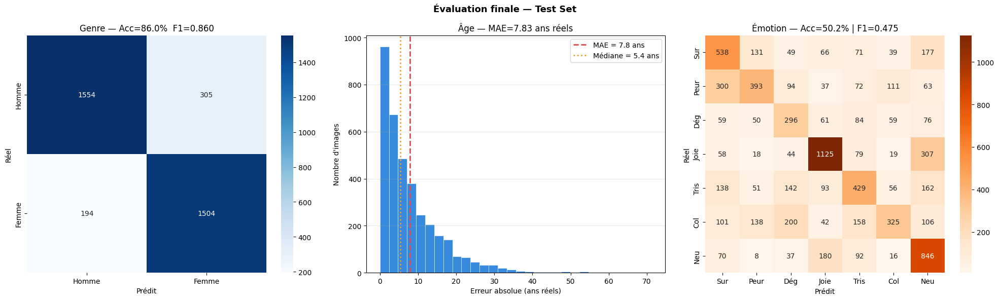


Colonnes history : ['epoch', 'train_loss', 'val_loss', 'train_loss_g', 'train_loss_a', 'train_loss_e', 'train_acc_gender', 'train_mae_age', 'train_acc_emotion', 'val_loss_g', 'val_loss_a', 'val_loss_e', 'val_acc_gender', 'val_mae_age', 'val_acc_emotion', 'val_f1_emotion']


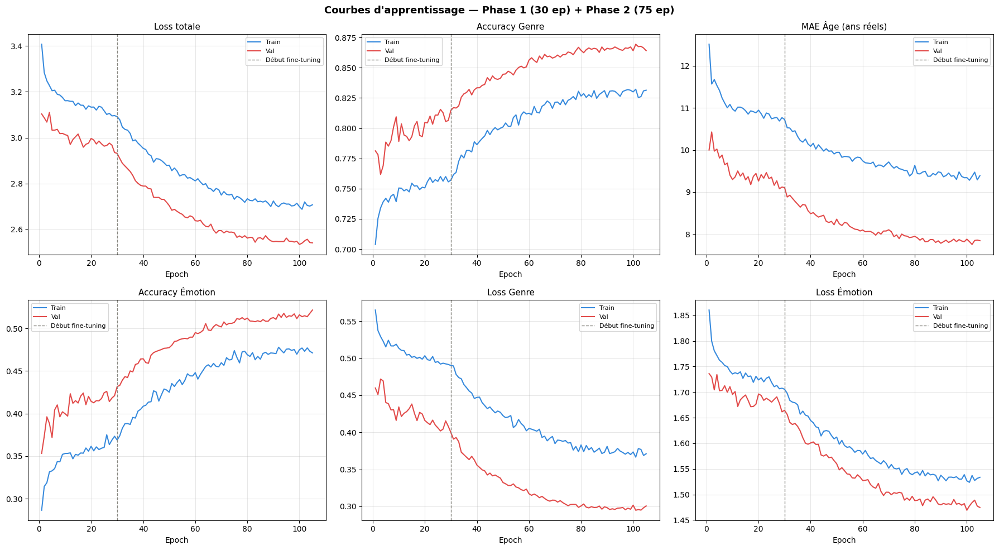

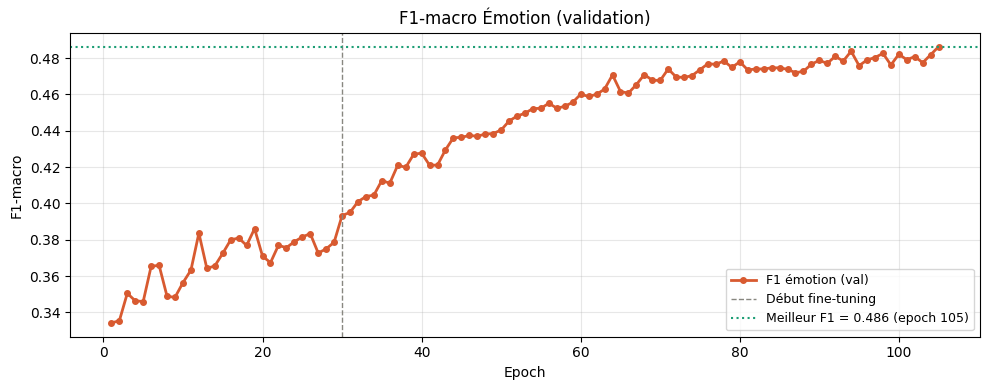


  ÉVALUATION TERMINÉE

  Genre   : Accuracy=86.0%  F1=0.860
  Âge     : MAE=7.83 ans réels  | Médiane=5.38 ans  | <5ans=47.8%
  Émotion : Accuracy=50.2%  F1=0.475

Fichiers sauvegardés :
  /kaggle/working/affectnet_clean.csv
  /kaggle/working/affectnet_distribution.png
  /kaggle/working/affectnet_exemples.png
  /kaggle/working/age_combined_distribution.png
  /kaggle/working/best_model.pth
  /kaggle/working/best_model_ft.pth
  /kaggle/working/combined_distribution.png
  /kaggle/working/confusion_matrices.png
  /kaggle/working/emotion_test_combined.csv
  /kaggle/working/emotion_train_combined.csv
  /kaggle/working/emotion_val_combined.csv
  /kaggle/working/f1_emotion_curve.png
  /kaggle/working/imdb_clean.csv
  /kaggle/working/imdb_distribution.png
  /kaggle/working/imdb_exemples.png
  /kaggle/working/learning_curves.png
  /kaggle/working/rafdb_clean.csv
  /kaggle/working/rafdb_distribution.png
  /kaggle/working/rafdb_exemples.png
  /kaggle/working/rafdb_vs_affectnet.png
  /kaggle/worki

In [23]:
# ==============================
# CHARGER LE MEILLEUR MODÈLE
# ==============================
model.load_state_dict(torch.load("/kaggle/working/best_model_ft.pth"))
model.eval()
print("Meilleur modèle chargé — évaluation sur TEST SET")

# ==============================
# ÉVALUATION COMPLÈTE
# ==============================
all_gender_preds,  all_gender_labels  = [], []
all_age_preds_norm, all_age_labels_norm = [], []   # valeurs normalisées [0,1]
all_emotion_preds, all_emotion_labels = [], []

with torch.no_grad():

    # ── UTKFace test ─────────────────────────────────────
    for imgs, genders, ages in utk_test_loader:
        imgs = imgs.to(device)
        out_g, out_a, _ = model(imgs)
        all_gender_preds.extend(out_g.argmax(1).cpu().tolist())
        all_gender_labels.extend(genders.tolist())
        all_age_preds_norm.extend(out_a.squeeze().cpu().tolist())   # normalisé
        all_age_labels_norm.extend(ages.tolist())                   # normalisé

    # ── Émotion test ─────────────────────────────────────
    for imgs, emotions in emotion_test_loader:
        imgs = imgs.to(device)
        _, _, out_e = model(imgs)
        all_emotion_preds.extend(out_e.argmax(1).cpu().tolist())
        all_emotion_labels.extend(emotions.tolist())

# ==============================
# DÉNORMALISATION DE L'ÂGE
# ==============================
all_age_preds  = [p * AGE_MAX for p in all_age_preds_norm]    # → ans réels
all_age_labels = [l * AGE_MAX for l in all_age_labels_norm]   # → ans réels

# ==============================
# MÉTRIQUES FINALES
# ==============================
acc_gender  = accuracy_score(all_gender_labels, all_gender_preds)
mae_age     = mean_absolute_error(all_age_labels, all_age_preds)   # en ans réels
acc_emotion = accuracy_score(all_emotion_labels, all_emotion_preds)
f1_gender   = f1_score(all_gender_labels,  all_gender_preds,
                        average="macro", zero_division=0)
f1_emotion  = f1_score(all_emotion_labels, all_emotion_preds,
                        average="macro", zero_division=0)

print("\n" + "=" * 52)
print("  RÉSULTATS FINAUX — TEST SET")
print("=" * 52)
print(f"\n  {'Tâche':<12} {'Métrique':>12} {'Score':>10}")
print(f"  {'─'*36}")
print(f"  {'Genre':<12} {'Accuracy':>12} {acc_gender*100:>9.1f}%")
print(f"  {'Genre':<12} {'F1-macro':>12} {f1_gender:>10.3f}")
print(f"  {'Âge':<12} {'MAE (ans)':>12} {mae_age:>10.2f}")   # ans réels
print(f"  {'Émotion':<12} {'Accuracy':>12} {acc_emotion*100:>9.1f}%")
print(f"  {'Émotion':<12} {'F1-macro':>12} {f1_emotion:>10.3f}")

# ==============================
# RAPPORT DÉTAILLÉ GENRE
# ==============================
print(f"\n{'─'*52}")
print("  RAPPORT GENRE")
print(f"{'─'*52}")
print(classification_report(
    all_gender_labels, all_gender_preds,
    target_names=["Homme", "Femme"], digits=3
))

# ==============================
# RAPPORT DÉTAILLÉ ÂGE — distribution des erreurs (en ANS RÉELS)
# ==============================
print(f"{'─'*52}")
print("  RAPPORT ÂGE (régression — valeurs en ans réels)")
print(f"{'─'*52}")
errors_age = [abs(p - r) for p, r in zip(all_age_preds, all_age_labels)]
print(f"  MAE global          : {mae_age:.2f} ans")
print(f"  Erreur médiane      : {np.median(errors_age):.2f} ans")
print(f"  Erreur max          : {np.max(errors_age):.1f} ans")
print(f"  % erreur < 5 ans    : {sum(e < 5  for e in errors_age)/len(errors_age)*100:.1f}%")
print(f"  % erreur < 10 ans   : {sum(e < 10 for e in errors_age)/len(errors_age)*100:.1f}%")

# ==============================
# RAPPORT DÉTAILLÉ ÉMOTION
# ==============================
print(f"\n{'─'*52}")
print("  RAPPORT ÉMOTION")
print(f"{'─'*52}")
emotion_names = ["Surprise","Peur","Dégoût","Joie","Tristesse","Colère","Neutre"]
print(classification_report(
    all_emotion_labels, all_emotion_preds,
    target_names=emotion_names, digits=3
))

# ==============================
# MATRICES DE CONFUSION + HISTOGRAMME ÂGE
# ==============================
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("Évaluation finale — Test Set", fontsize=13, fontweight="bold")

# Genre
cm_g = confusion_matrix(all_gender_labels, all_gender_preds)
sns.heatmap(cm_g, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Homme","Femme"],
            yticklabels=["Homme","Femme"], ax=axes[0])
axes[0].set_title(f"Genre — Acc={acc_gender*100:.1f}%  F1={f1_gender:.3f}")
axes[0].set_ylabel("Réel")
axes[0].set_xlabel("Prédit")

# Âge — histogramme des erreurs EN ANS RÉELS
axes[1].hist(errors_age, bins=30, color="#378ADD",
             edgecolor="white", linewidth=0.4)
axes[1].axvline(mae_age, color="#E24B4A", linestyle="--",
                linewidth=2, label=f"MAE = {mae_age:.1f} ans")
axes[1].axvline(np.median(errors_age), color="#EF9F27", linestyle=":",
                linewidth=2, label=f"Médiane = {np.median(errors_age):.1f} ans")
axes[1].set_title(f"Âge — MAE={mae_age:.2f} ans réels")
axes[1].set_xlabel("Erreur absolue (ans réels)")
axes[1].set_ylabel("Nombre d'images")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

# Émotion
cm_e = confusion_matrix(all_emotion_labels, all_emotion_preds)
sns.heatmap(cm_e, annot=True, fmt="d", cmap="Oranges",
            xticklabels=["Sur","Peur","Dég","Joie","Tris","Col","Neu"],
            yticklabels=["Sur","Peur","Dég","Joie","Tris","Col","Neu"],
            ax=axes[2])
axes[2].set_title(f"Émotion — Acc={acc_emotion*100:.1f}% | F1={f1_emotion:.3f}")
axes[2].set_ylabel("Réel")
axes[2].set_xlabel("Prédit")

plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrices.png", dpi=120, bbox_inches="tight")
plt.show()

# ==============================
# COURBES D'APPRENTISSAGE
# ==============================
df_history = pd.DataFrame(history)
print("\nColonnes history :", list(df_history.columns))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle(f"Courbes d'apprentissage — Phase 1 ({N_EPOCHS_PHASE1} ep) "
             f"+ Phase 2 ({N_EPOCHS_PHASE2} ep)",
             fontsize=13, fontweight="bold")

metrics = [
    ("loss",        "Loss totale"),
    ("acc_gender",  "Accuracy Genre"),
    ("mae_age",     "MAE Âge (ans réels)"),
    ("acc_emotion", "Accuracy Émotion"),
    ("loss_g",      "Loss Genre"),
    ("loss_e",      "Loss Émotion"),
]

for i, (key, title) in enumerate(metrics):
    ax        = axes[i // 3][i % 3]
    train_key = f"train_{key}"
    val_key   = f"val_{key}"

    if train_key in df_history.columns:
        ax.plot(df_history["epoch"], df_history[train_key],
                label="Train", color="#378ADD", linewidth=1.5)
    if val_key in df_history.columns:
        ax.plot(df_history["epoch"], df_history[val_key],
                label="Val", color="#E24B4A", linewidth=1.5)

    ax.axvline(x=N_EPOCHS_PHASE1, color="#888780", linestyle="--",
               linewidth=1, label="Début fine-tuning")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Epoch")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/learning_curves.png", dpi=120, bbox_inches="tight")
plt.show()

# F1 émotion validation
if "val_f1_emotion" in df_history.columns:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(df_history["epoch"], df_history["val_f1_emotion"],
            color="#D85A30", linewidth=2, marker="o", markersize=4,
            label="F1 émotion (val)")
    ax.axvline(x=N_EPOCHS_PHASE1, color="#888780", linestyle="--",
               linewidth=1, label="Début fine-tuning")
    best_f1 = df_history["val_f1_emotion"].max()
    best_ep = df_history.loc[df_history["val_f1_emotion"].idxmax(), "epoch"]
    ax.axhline(y=best_f1, color="#1D9E75", linestyle=":",
               linewidth=1.5, label=f"Meilleur F1 = {best_f1:.3f} (epoch {best_ep:.0f})")
    ax.set_title("F1-macro Émotion (validation)", fontsize=12)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("F1-macro")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("/kaggle/working/f1_emotion_curve.png", dpi=120, bbox_inches="tight")
    plt.show()

# ==============================
# RÉSUMÉ FINAL
# ==============================
print("\n" + "=" * 52)
print("  ÉVALUATION TERMINÉE")
print("=" * 52)
print(f"\n  Genre   : Accuracy={acc_gender*100:.1f}%  F1={f1_gender:.3f}")
print(f"  Âge     : MAE={mae_age:.2f} ans réels  "
      f"| Médiane={np.median(errors_age):.2f} ans  "
      f"| <5ans={sum(e<5 for e in errors_age)/len(errors_age)*100:.1f}%")
print(f"  Émotion : Accuracy={acc_emotion*100:.1f}%  F1={f1_emotion:.3f}")

print("\nFichiers sauvegardés :")
for f in sorted(os.listdir("/kaggle/working")):
    if f.endswith((".png", ".pth", ".csv")):
        print(f"  /kaggle/working/{f}")

# 12. TEST AVEC NEW DATASET "INFERENCE"


  INFÉRENCE — IMAGES PERSONNELLES
  Images trouvées : 5
    asian.JPG
    backlit.JPG
    cry.JPG
    multifaces.JPG
    sunlight.JPG


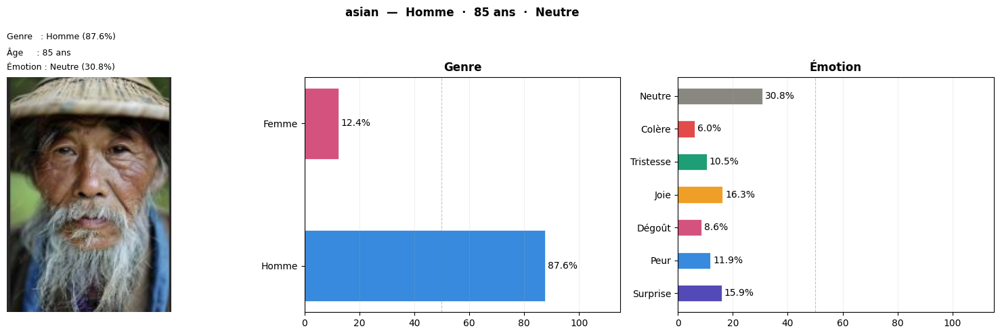

Image : asian
  Genre   → Homme (87.6%)
  Âge     → 85 ans
  Émotion → Neutre (30.8%)



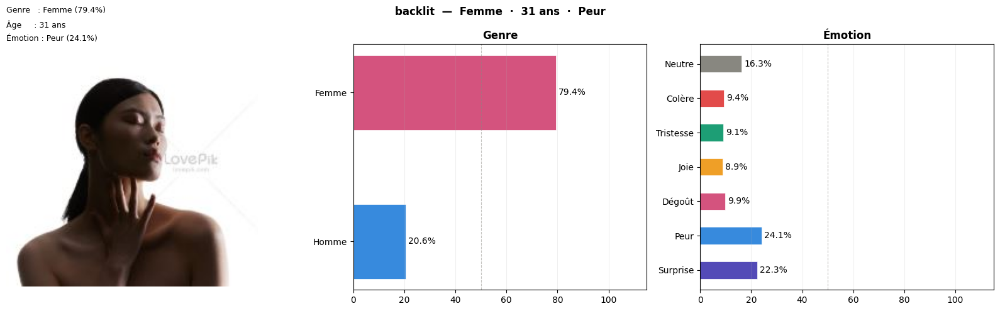

Image : backlit
  Genre   → Femme (79.4%)
  Âge     → 31 ans
  Émotion → Peur (24.1%)



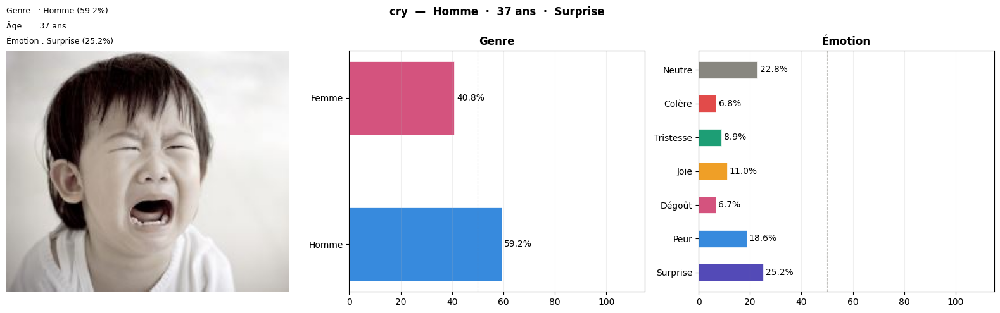

Image : cry
  Genre   → Homme (59.2%)
  Âge     → 37 ans
  Émotion → Surprise (25.2%)



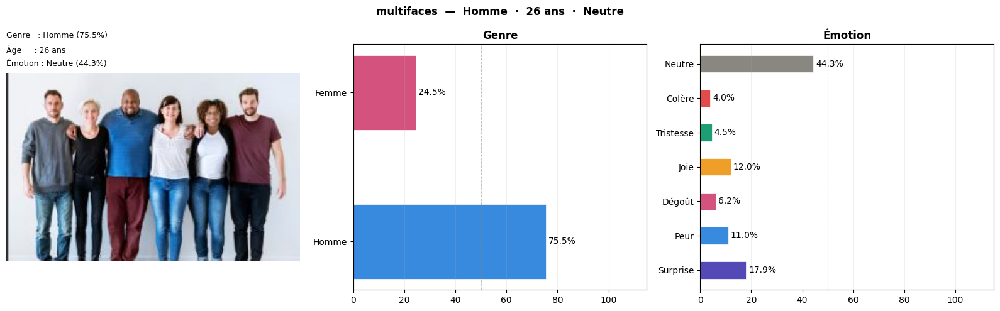

Image : multifaces
  Genre   → Homme (75.5%)
  Âge     → 26 ans
  Émotion → Neutre (44.3%)



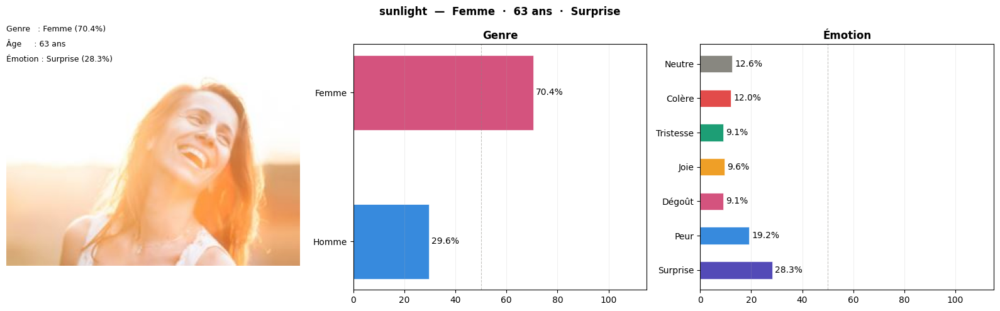

Image : sunlight
  Genre   → Femme (70.4%)
  Âge     → 63 ans
  Émotion → Surprise (28.3%)

Inférence terminée ✅


In [24]:
# ==============================
# INFÉRENCE — IMAGES PERSONNELLES
# ==============================
import os
import torch
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

PATH_IMAGES = "/kaggle/input/datasets/imaneougni/test-inference"

# Labels et couleurs
gender_labels  = {0: "Homme", 1: "Femme"}
emotion_labels = {0: "Surprise", 1: "Peur",  2: "Dégoût",
                  3: "Joie",     4: "Tristesse", 5: "Colère", 6: "Neutre"}
emotion_colors = ["#534AB7","#378ADD","#D4537E",
                  "#EF9F27","#1D9E75","#E24B4A","#888780"]
gender_colors  = ["#378ADD", "#D4537E"]

# Lister les images
images_list = [
    os.path.join(PATH_IMAGES, f)
    for f in sorted(os.listdir(PATH_IMAGES))
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print(f"\n{'='*55}")
print(f"  INFÉRENCE — IMAGES PERSONNELLES")
print(f"{'='*55}")
print(f"  Images trouvées : {len(images_list)}")
for img in images_list:
    print(f"    {os.path.basename(img)}")

# ==============================
# FONCTION PREDICT — RÉGRESSION ÂGE
# ==============================
def predict(image_path):
    image_pil    = Image.open(image_path).convert("RGB")
    image_tensor = val_test_transform(image_pil)
    image_tensor = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        out_gender, out_age, out_emotion = model(image_tensor)

    prob_gender  = F.softmax(out_gender,  dim=1).squeeze().cpu().numpy()
    age_pred = denormalize_age(out_age.squeeze().cpu().item())
    age_pred = max(0.0, min(AGE_MAX, age_pred))
    prob_emotion = F.softmax(out_emotion, dim=1).squeeze().cpu().numpy()

    return {
        "image"        : image_pil,
        "pred_gender"  : int(prob_gender.argmax()),
        "pred_age"     : age_pred,                       # ← float
        "pred_emotion" : int(prob_emotion.argmax()),
        "prob_gender"  : prob_gender,
        "prob_emotion" : prob_emotion,
    }

# ==============================
# FONCTION VISUALISATION — RÉGRESSION ÂGE
# ==============================
def visualize_prediction(result, image_name=""):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))  # ← 3 plots au lieu de 4

    age_str = f"{result['pred_age']:.0f} ans"
    titre = (
        f"{image_name}  —  "
        f"{gender_labels[result['pred_gender']]}  ·  "
        f"{age_str}  ·  "
        f"{emotion_labels[result['pred_emotion']]}"
    )
    fig.suptitle(titre, fontsize=12, fontweight="bold")

    # ── Image originale ──────────────────────────────────
    axes[0].imshow(result["image"])
    axes[0].axis("off")
    summary = (
        f"Genre   : {gender_labels[result['pred_gender']]} "
        f"({result['prob_gender'][result['pred_gender']]*100:.1f}%)\n"
        f"Âge     : {result['pred_age']:.0f} ans\n"
        f"Émotion : {emotion_labels[result['pred_emotion']]} "
        f"({result['prob_emotion'][result['pred_emotion']]*100:.1f}%)"
    )
    axes[0].set_title(summary, fontsize=9, loc="left",
                      pad=8, linespacing=1.8)

    # ── Barre genre ───────────────────────────────────────
    probs_g = result["prob_gender"] * 100
    bars_g  = axes[1].barh([gender_labels[i] for i in range(2)],
                            probs_g, color=gender_colors,
                            edgecolor="white", linewidth=0.5, height=0.5)
    for bar, val in zip(bars_g, probs_g):
        axes[1].text(val + 1, bar.get_y() + bar.get_height()/2,
                     f"{val:.1f}%", va="center", fontsize=10)
    axes[1].set_xlim(0, 115)
    axes[1].set_title("Genre", fontweight="bold")
    axes[1].axvline(x=50, color="#888780", linestyle="--",
                    linewidth=0.8, alpha=0.5)
    axes[1].grid(axis="x", alpha=0.2)

    # ── Barre émotion ─────────────────────────────────────
    probs_e = result["prob_emotion"] * 100
    bars_e  = axes[2].barh([emotion_labels[i] for i in range(7)],
                            probs_e, color=emotion_colors,
                            edgecolor="white", linewidth=0.5, height=0.5)
    for bar, val in zip(bars_e, probs_e):
        axes[2].text(val + 1, bar.get_y() + bar.get_height()/2,
                     f"{val:.1f}%", va="center", fontsize=10)
    axes[2].set_xlim(0, 115)
    axes[2].set_title("Émotion", fontweight="bold")
    axes[2].axvline(x=50, color="#888780", linestyle="--",
                    linewidth=0.8, alpha=0.5)
    axes[2].grid(axis="x", alpha=0.2)

    plt.tight_layout()
    plt.savefig(
        f"/kaggle/working/inference_{image_name}.png",
        dpi=120, bbox_inches="tight"
    )
    plt.show()

# ==============================
# LANCER L'INFÉRENCE
# ==============================
for image_path in images_list:
    image_name = os.path.splitext(os.path.basename(image_path))[0]
    result     = predict(image_path)
    visualize_prediction(result, image_name=image_name)

    print(f"Image : {image_name}")
    print(f"  Genre   → {gender_labels[result['pred_gender']]} "
          f"({result['prob_gender'][result['pred_gender']]*100:.1f}%)")
    print(f"  Âge     → {result['pred_age']:.0f} ans")        # ← valeur exacte
    print(f"  Émotion → {emotion_labels[result['pred_emotion']]} "
          f"({result['prob_emotion'][result['pred_emotion']]*100:.1f}%)")
    print()

print("Inférence terminée ✅")